# Project 2

Welcome to the second NLP1 project. The goal of the second tutorial was to get you familiar with using pre-trained embeddings and moving towards a compositional encoder for text classification.

Given the skills you have developed in the last week, you will now be applying them within the dataset and task you have chosen during Project 1. You will be applying hands-on the experiments you have already explored in the Tutorial 2, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and errors analyses, and tackling your own research questions. 


The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

# Get to work!

1. Find a word embedding model that is appropriate for your dataset. Think about the language, the kind of text you are working with. Find evidence that your choice is a good one: 
    * Can you tokenize your texts in a way coherent with the definition of a token in the embedding model?
    * Does the model's vocabulary give enough coverage to the words in your texts? etc.
2. Explore what your chosen word embedding model captures. Some things you might consider: 
    * Is it good at representing interesting similarities (re to your choice of task)? J
    * Have you found task-specific evidence that it's better than some other reasonable alternative?
    * Do you know about limitations of this model?
    * Any limitations that you find particularly troubling for your task? 
3. Experiment with the embed-and-pool approach.  
    * What design choices have meaningful impact in classification performance (eg, embedding size, architecture design, optimisation parameters), if any?
    * Is this better than what you could achieve last week? In other words, did pretrained embeddings add to your design?
4. Experiment with a recurrent encoder (GRU or LSTM). 
    * What design choices have meaningful impact in classification performance, if any?
    * Did you investigate the impact of data size, embedding parameters (trained or not, fixed or trainable, etc)?
    * Did you struggle with over-fitting?
    * How far can this approach go? Are you able to improve meaningfully on embed-and-pool?
5. We make decisions under uncertainty all the time, are you gathering enough information to substantiate your choices? Various things can lead to small differences in results, and these differences are not always consistent. Here are some things to think about:
    * How did you structure you hyperparameter search?
    * Are you keeping an eye on experimental variance?
6. Experiment with error analysis and try to discover what characteristics of input texts are predictive of performance differences across major design choices. 
    * What analysis features did you come up with?
    * Which ones did you manage to test and how did that go?
    * What would you prioritise in the future in order to improve your systems?

Be mindful that you will be using your experiments to write up your final blog, so make sure your code is clean and neat!

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

# Tips

## Pretrained embedding models

We will post a list with some options for you. 

## Features for analysis

Features that you can interpret as an aspect of _complexity_ in light of your task's goals.

- length
- presence of rare/common words, including unknown words
- syntactic features (like parts-of-speech, syntactic complexity, syntactic voice, presence of negation, etc.)
- semantic features (eg, the average similarity of the text to training documents or some curated set of training documents, presence of words in certain semantic classes, etc.)
- task-specific features (eg, 
- model-specific features (eg, predicted label, probability assigned to predicted label, number of parameters or layers or some other model descriptor)

# Dataset and task

We continue with the English six-way emotion-classification task selected in Project 1. The data come from `dair-ai/emotion`, and the labels are sadness, joy, love, anger, fear, and surprise. The original train and validation splits form a pool of 18,000 texts. Before any vocabulary construction, tuning, or training, we carve out a class-balanced devtest set containing 100 texts per class (600 total). The devtest is reserved exclusively for error analysis: no model trains on it, and no hyperparameter, epoch, or model-selection choice is made using it. The remaining 17,400 texts are used for cross-validation. The original 2,000-text test set remains untouched until final evaluation.

In [89]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# The notebook is intended to run from the part2 directory.
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1

## Saving results locally

Everything this notebook produces is stored under `part2/results/` (which is git-ignored, so nothing is pushed to GitHub):

* `results/tables/*.csv`: every results table, written with `save_table`;
* `results/figures/*.png`: every figure, saved automatically whenever `plt.show()` is called (the file name is taken from the figure's title);
* `results/cache/*.pkl`: the outputs of expensive training runs, via `load_or_compute`. Re-running a training cell loads the stored results instead of retraining. The cache file name contains a hash of both `DATA_VERSION` and the experiment configuration, so changing the data split or a setting automatically triggers a fresh run. Set `RERUN_EXPERIMENTS = True` to force retraining;
* trained models (`.pt` + `.json`), the data-versioned Optuna study (`results/optuna.db`) and the data-versioned LSTM score file are stored by the respective sections.

In [ ]:
import hashlib
import json
import pickle
import re

import matplotlib.pyplot as plt

RESULTS_DIR = Path("results")
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"
CACHE_DIR = RESULTS_DIR / "cache"
for directory in (TABLES_DIR, FIGURES_DIR, CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RERUN_EXPERIMENTS = False   # True: ignore cached training results and retrain


def save_table(df, name, index=True):
    """Write a results table to results/tables/<name>.csv."""
    df.to_csv(TABLES_DIR / f"{name}.csv", index=index)


def _slug(text):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")[:80] or "figure"


def _figure_name(fig):
    if fig._suptitle is not None and fig._suptitle.get_text():
        return _slug(fig._suptitle.get_text())
    for axis in fig.axes:
        if axis.get_title():
            return _slug(axis.get_title())
    return f"figure_{fig.number}"


if not getattr(plt.show, "_saves_figures", False):
    _original_show = plt.show

    def _show_and_save(*args, **kwargs):
        """plt.show() that first saves every open figure to results/figures/."""
        for number in plt.get_fignums():
            fig = plt.figure(number)
            fig.savefig(FIGURES_DIR / f"{_figure_name(fig)}.png", dpi=150, bbox_inches="tight")
        return _original_show(*args, **kwargs)

    _show_and_save._saves_figures = True
    plt.show = _show_and_save   # also covers helpers such as part1.analysis.plot_box_and_points


def load_or_compute(name, compute, key):
    """
    Return the cached result of `compute()` for this data split and experiment
    configuration (`key`), or run it and store the result in
    results/cache/<name>-<hash>.pkl.
    """
    cache_key = {"data_version": globals().get("DATA_VERSION"), "key": key}
    digest = hashlib.sha1(
        json.dumps(cache_key, sort_keys=True, default=str).encode()
    ).hexdigest()[:10]
    cache_path = CACHE_DIR / f"{name}-{digest}.pkl"
    if cache_path.exists() and not RERUN_EXPERIMENTS:
        print(f"Loaded cached results from {cache_path}")
        with open(cache_path, "rb") as cache_file:
            return pickle.load(cache_file)
    result = compute()
    with open(cache_path, "wb") as cache_file:
        pickle.dump(result, cache_file)
    print(f"Saved results to {cache_path}")
    return result

In [ ]:
from datasets import concatenate_datasets, load_dataset
import pandas as pd

outcome_space = part1.clslib.NamedClasses(
    ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
)

dataset = load_dataset("dair-ai/emotion", "split")
training_pool = concatenate_datasets(
    [dataset["train"], dataset["validation"]]
)
del dataset["validation"]

DEVTEST_PER_CLASS = 100
DEVTEST_SEED = 0
rng = np.random.default_rng(DEVTEST_SEED)
pool_labels = np.asarray(training_pool["label"])
devtest_indices = np.sort(np.concatenate([
    rng.choice(
        np.flatnonzero(pool_labels == label_id),
        size=DEVTEST_PER_CLASS,
        replace=False,
    )
    for label_id in range(len(outcome_space))
]))
train_indices = np.setdiff1d(
    np.arange(len(training_pool)), devtest_indices
)

dataset["devtest"] = training_pool.select(devtest_indices)
dataset["train"] = training_pool.select(train_indices)
DATA_VERSION = f"devtest{DEVTEST_PER_CLASS}pc-seed{DEVTEST_SEED}"

if "TABLES_DIR" not in globals():
    TABLES_DIR = Path("results") / "tables"
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
pd.DataFrame({
    "pool_index": devtest_indices,
    "label": dataset["devtest"]["label"],
    "text": dataset["devtest"]["text"],
}).to_csv(
    TABLES_DIR / f"devtest_{DATA_VERSION}.csv", index=False
)

print(outcome_space)
print(dataset)
print(DATA_VERSION)

In [92]:
for index in [0, 2]:
    example = dataset["train"][index]
    print(f"Text: {example['text']}")
    print(f"Gold label (id): {example['label']}")
    print(f"Gold label (name): {outcome_space.name(example['label'])}\n")

Text: i didnt feel humiliated
Gold label (id): 0
Gold label (name): sadness

Text: im grabbing a minute to post i feel greedy wrong
Gold label (id): 3
Gold label (name): anger



## Class distributions

The class distribution is imbalanced: joy and sadness are the largest classes, while surprise is the smallest. This motivates reporting macro-F1 in addition to accuracy. Every neural model below is trained with inverse-frequency class-weighted negative log likelihood. The weights are recomputed from the training partition of each fold, so validation and test labels never influence the loss.

In [ ]:
for split_name in ["train", "devtest", "test"]:
    labels = np.asarray(dataset[split_name]["label"])
    class_counts = np.bincount(labels, minlength=len(outcome_space))
    class_percentages = 100 * class_counts / labels.size

    print(f"---- {split_name} set (N={labels.size}) ----")
    for label_id, label_name in enumerate(outcome_space.names):
        print(
            f"{label_name.title()}: {class_counts[label_id]} examples "
            f"({class_percentages[label_id]:.2f}%)"
        )

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.pie(
        class_counts,
        labels=[
            f"{name.title()}\n(n={count})"
            for name, count in zip(outcome_space.names, class_counts)
        ],
        autopct="%1.1f%%",
        startangle=90,
        counterclock=False,
        wedgeprops={"edgecolor": "white", "linewidth": 1},
    )
    ax.set_title(f"{split_name}-set class distribution (N={labels.size})")
    ax.axis("equal")
    plt.tight_layout()
    plt.show()

## Text-length distributions

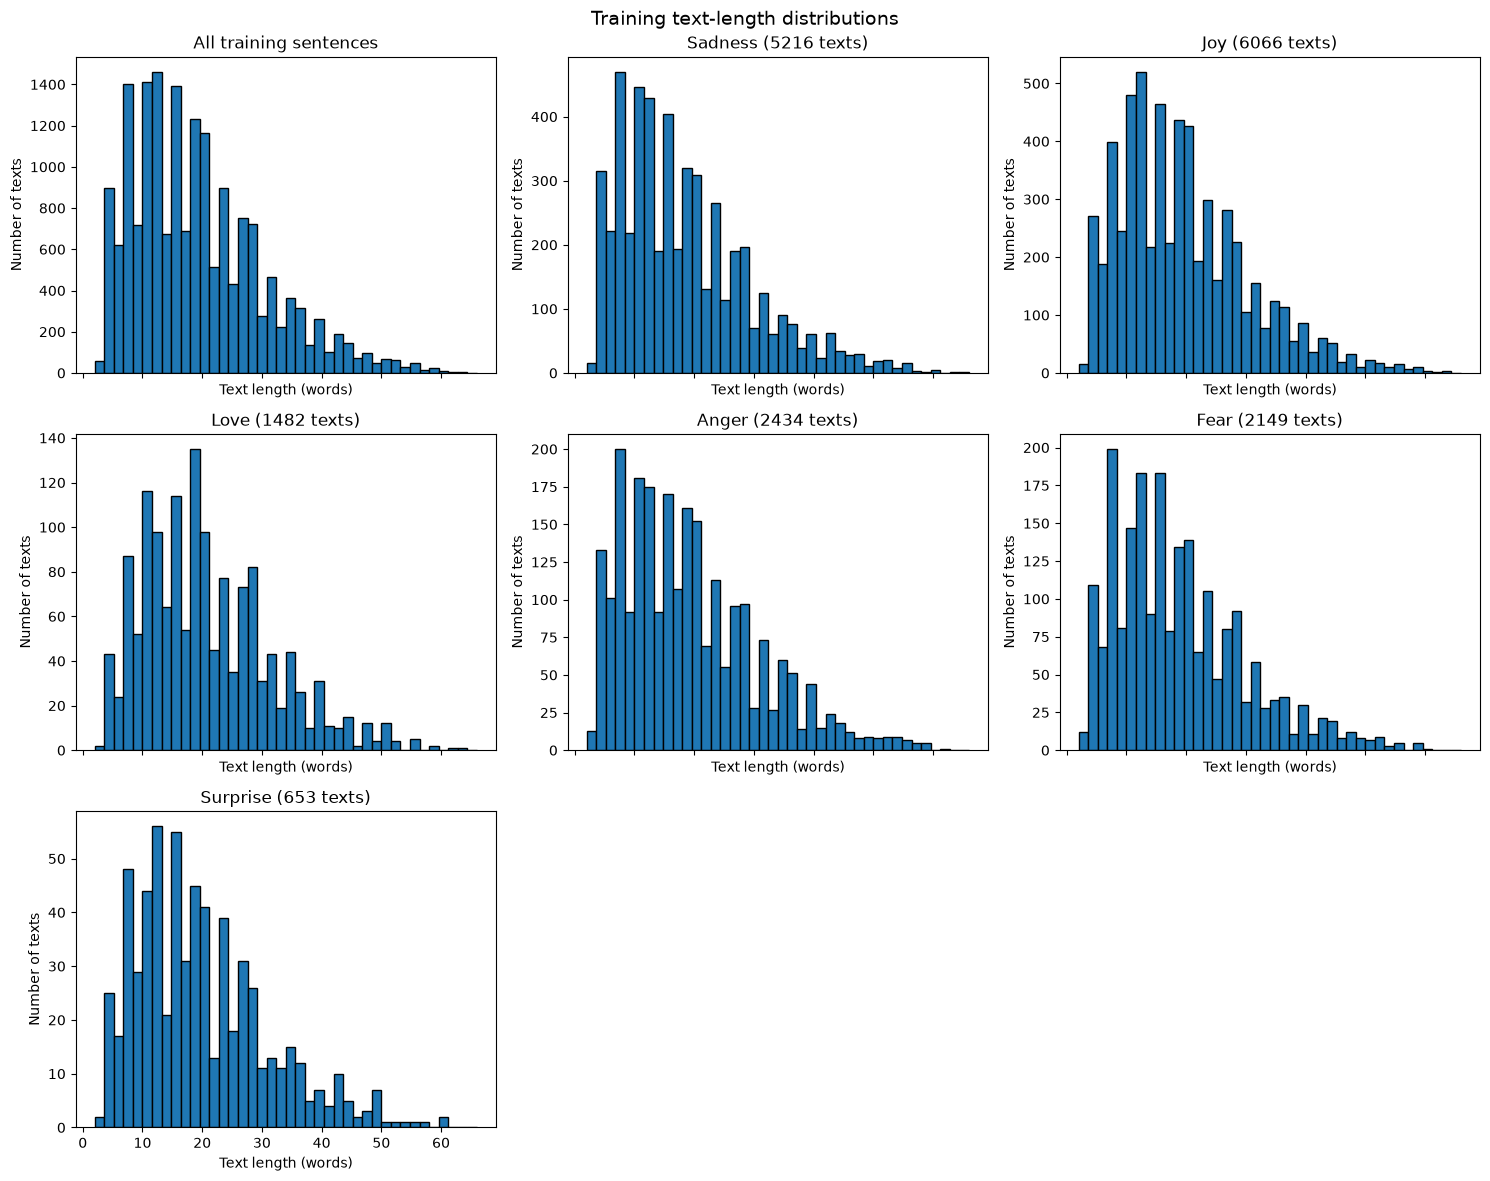

In [94]:
import math

train_texts = dataset["train"]["text"]
train_labels = np.asarray(dataset["train"]["label"])
text_lengths = np.asarray([len(text.split()) for text in train_texts])

num_plots = len(outcome_space) + 1
ncols = 3
nrows = math.ceil(num_plots / ncols)
fig, axes = plt.subplots(
    nrows=nrows, ncols=ncols, figsize=(5 * ncols, 4 * nrows), sharex=True
)
axes = np.atleast_1d(axes).flatten()
bin_edges = np.histogram_bin_edges(text_lengths, bins=40)

axes[0].hist(text_lengths, bins=bin_edges, edgecolor="black")
axes[0].set_title("All training sentences")
axes[0].set_xlabel("Text length (words)")
axes[0].set_ylabel("Number of texts")

for label_id, label_name in enumerate(outcome_space.names):
    class_lengths = text_lengths[train_labels == label_id]
    axis = axes[label_id + 1]
    axis.hist(class_lengths, bins=bin_edges, edgecolor="black")
    axis.set_title(f"{label_name.title()} ({len(class_lengths)} texts)")
    axis.set_xlabel("Text length (words)")
    axis.set_ylabel("Number of texts")

for axis in axes[num_plots:]:
    axis.set_visible(False)

fig.suptitle("Training text-length distributions", fontsize=14)
plt.tight_layout()
plt.show()

# Get to Work 1: Choosing a pretrained embedding model

Project 1 already established the dataset, a lowercase word-level tokenization procedure, and working loaders for GloVe embeddings. We transfer those components here as the starting point for selecting the Project 2 embedding model.

The dataset is English and consists of short, informal, first-person texts. We therefore consider two existing candidates: GloVe 6B, trained on Wikipedia and Gigaword, and GloVe Twitter 27B, trained on Twitter data. The Twitter model is intuitively better matched to forms such as `im` and `didnt`, but vocabulary coverage and task evidence still need to confirm that intuition.

## Word-level tokenization

The tokenizer lowercases the input and separates words and punctuation before vocabulary lookup. This produces word-like units compatible with the word-level entries used by GloVe. The 1,000-token cap is inherited from Project 1 and will need to be reconsidered when measuring embedding coverage.

In [95]:
from tokenizers import Tokenizer
from tokenizers.models import WordLevel
from tokenizers.normalizers import Lowercase
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.trainers import WordLevelTrainer

vocab_size = 1000
min_frequency = 2
unk_token = "??"

tokenizer = Tokenizer(WordLevel(unk_token=unk_token))
tokenizer.normalizer = Lowercase()
tokenizer.pre_tokenizer = Whitespace()
trainer = WordLevelTrainer(
    vocab_size=vocab_size,
    min_frequency=min_frequency,
    special_tokens=[unk_token],
)
tokenizer.train_from_iterator(train_texts, trainer=trainer)

example_text = train_texts[0]
example_encoding = tokenizer.encode(example_text)
print("Original text:", example_text)
print("Tokens:", example_encoding.tokens)
print("Token IDs:", example_encoding.ids)

Original text: i didnt feel humiliated
Tokens: ['i', 'didnt', 'feel', 'humiliated']
Token IDs: [1, 139, 2, 659]


Unique normalized training tokens: 16,196
Tokens occurring at least 2 times: 7,902
Learned vocabulary size: 1,000
Eligible tokens excluded by the cap: 6,903


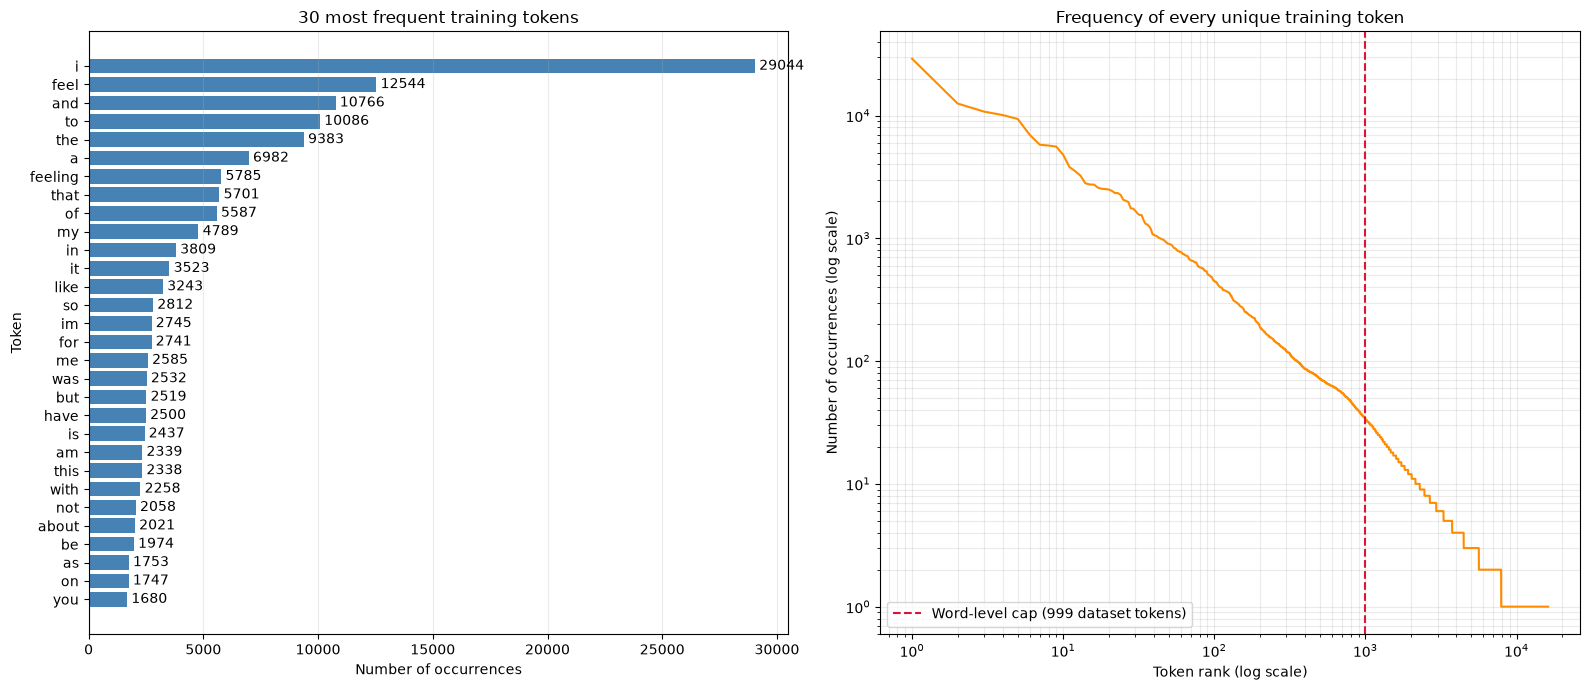

In [96]:
from collections import Counter

word_counts = Counter()
for document in train_texts:
    normalized = tokenizer.normalizer.normalize_str(document)
    pretokenized = tokenizer.pre_tokenizer.pre_tokenize_str(normalized)
    word_counts.update(token for token, _ in pretokenized)

num_unique_words = len(word_counts)
num_eligible_words = sum(
    frequency >= min_frequency for frequency in word_counts.values()
)
word_level_cap = vocab_size - 1
num_words_removed_by_cap = max(0, num_eligible_words - word_level_cap)

print(f"Unique normalized training tokens: {num_unique_words:,}")
print(f"Tokens occurring at least {min_frequency} times: {num_eligible_words:,}")
print(f"Learned vocabulary size: {len(tokenizer.get_vocab()):,}")
print(f"Eligible tokens excluded by the cap: {num_words_removed_by_cap:,}")

top_n = 30
top_words = word_counts.most_common(top_n)
words, counts = zip(*reversed(top_words))
all_counts = sorted(word_counts.values(), reverse=True)
ranks = range(1, len(all_counts) + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
bars = axes[0].barh(words, counts, color="steelblue")
axes[0].bar_label(bars, padding=3, fmt="%d")
axes[0].set_title(f"{top_n} most frequent training tokens")
axes[0].set_xlabel("Number of occurrences")
axes[0].set_ylabel("Token")
axes[0].grid(axis="x", alpha=0.25)

axes[1].loglog(ranks, all_counts, color="darkorange")
axes[1].axvline(
    word_level_cap, color="crimson", linestyle="--",
    label=f"Word-level cap ({word_level_cap:,} dataset tokens)",
)
axes[1].set_title("Frequency of every unique training token")
axes[1].set_xlabel("Token rank (log scale)")
axes[1].set_ylabel("Number of occurrences (log scale)")
axes[1].grid(alpha=0.25, which="both")
axes[1].legend()
plt.tight_layout()
plt.show()

## Existing GloVe candidates from Project 1

Project 1 established working loaders for both Twitter GloVe and GloVe 6B. For a controlled comparison in Project 2, `shared_glove_dim` selects **one common dimensionality for both models**, so embedding dimensionality is held constant while the training corpus changes. Set it to 50, 100, or 200 and rerun the notebook. The paths below reuse the downloaded files from the `part1/glove` directory. Loading a candidate constructs an embedding matrix aligned with the tokenizer vocabulary; rows without a matching pretrained vector remain zero.

In [97]:
def embedding_for_vocab(filepath, word_index, embedding_dim):
    embedding_matrix = np.zeros((len(word_index), embedding_dim), dtype=np.float32)
    with open(filepath, encoding="utf8") as embedding_file:
        for line in embedding_file:
            word, *vector = line.split()
            if word in word_index:
                embedding_matrix[word_index[word]] = np.asarray(
                    vector[:embedding_dim], dtype=np.float32
                )
    return embedding_matrix

glove_root = root / "part1" / "glove"

# Change this one value to use the same dimensionality for both models.
# The dimensions available for both GloVe collections are 50, 100, and 200.
shared_glove_dim = 50
common_glove_dimensions = {50, 100, 200}
if shared_glove_dim not in common_glove_dimensions:
    raise ValueError(
        f"shared_glove_dim must be one of {sorted(common_glove_dimensions)}, "
        f"not {shared_glove_dim}."
    )

embedding_candidates = {
    "glove_twitter": (
        glove_root / "glove.twitter.27B"
        / f"glove.twitter.27B.{shared_glove_dim}d.txt",
        shared_glove_dim,
    ),
    "glove_6B": (
        glove_root / f"glove.6B.{shared_glove_dim}d.txt",
        shared_glove_dim,
    ),
}

for name, (path, dimension) in embedding_candidates.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing embedding file: {path}")
    print(f"{name}: dimension={dimension}, path={path}")

glove_twitter: dimension=50, path=/Users/gregory/Documents/uva/period-2/nlp/code/nlp-assignment-1/part1/glove/glove.twitter.27B/glove.twitter.27B.50d.txt
glove_6B: dimension=50, path=/Users/gregory/Documents/uva/period-2/nlp/code/nlp-assignment-1/part1/glove/glove.6B.50d.txt


## Count the dataset words

In [98]:
from collections import Counter

def tokenize_for_coverage(text, tokenizer):
    normalized = tokenizer.normalizer.normalize_str(text)
    return [
        token
        for token, _ in tokenizer.pre_tokenizer.pre_tokenize_str(normalized)
    ]

def corpus_word_counts(texts, tokenizer):
    counts = Counter()

    for text in texts:
        counts.update(tokenize_for_coverage(text, tokenizer))

    return counts

train_word_counts = corpus_word_counts(
    dataset["train"]["text"],
    tokenizer,
)

print(f"Unique word types: {len(train_word_counts):,}")
print(f"Total word tokens: {sum(train_word_counts.values()):,}")

Unique word types: 16,196
Total word tokens: 344,393


## Embedding-vocabulary coverage

We measure coverage on the complete pretokenized training corpus, before applying the 1,000-token vocabulary cap. This is important: measuring only the learned tokenizer vocabulary would hide words converted to `??` even when the pretrained model contains them.

We report **type coverage** (the proportion of distinct dataset words present in the embedding vocabulary), **token coverage** (the proportion of all word occurrences covered), and document-level coverage. Token coverage is especially important because rare misspellings can lower type coverage without affecting many texts.

In [99]:
import pandas as pd

def find_covered_words(embedding_path, required_words):
    """Return dataset words that occur in a pretrained embedding vocabulary."""
    required_words = set(required_words)
    covered_words = set()

    with open(embedding_path, encoding="utf8") as embedding_file:
        for line in embedding_file:
            word = line.split(maxsplit=1)[0]
            if word in required_words:
                covered_words.add(word)

    return covered_words


def coverage_statistics(texts, word_counts, covered_words, tokenizer):
    total_tokens = sum(word_counts.values())
    covered_tokens = sum(
        frequency
        for word, frequency in word_counts.items()
        if word in covered_words
    )

    document_coverages = []
    for text in texts:
        tokens = tokenize_for_coverage(text, tokenizer)
        if tokens:
            document_coverages.append(
                sum(token in covered_words for token in tokens) / len(tokens)
            )

    document_coverages = np.asarray(document_coverages)
    return {
        "type_coverage": len(covered_words) / len(word_counts),
        "token_coverage": covered_tokens / total_tokens,
        "mean_document_coverage": document_coverages.mean(),
        "fully_covered_documents": np.mean(document_coverages == 1.0),
        "documents_below_80pct": np.mean(document_coverages < 0.8),
        "covered_types": len(covered_words),
        "total_types": len(word_counts),
        "covered_tokens": covered_tokens,
        "total_tokens": total_tokens,
    }

In [100]:
covered_words_by_model = {}
coverage_rows = []

for model_name, (embedding_path, _) in embedding_candidates.items():
    covered_words = find_covered_words(
        embedding_path,
        train_word_counts,
    )
    covered_words_by_model[model_name] = covered_words
    coverage_rows.append({
        "model": model_name,
        **coverage_statistics(
            train_texts, train_word_counts, covered_words, tokenizer
        ),
    })

coverage_df = (
    pd.DataFrame(coverage_rows)
    .set_index("model")
    .sort_values("token_coverage", ascending=False)
)

save_table(coverage_df, "coverage")
display(coverage_df.style.format({
    "type_coverage": "{:.2%}",
    "token_coverage": "{:.2%}",
    "mean_document_coverage": "{:.2%}",
    "fully_covered_documents": "{:.2%}",
    "documents_below_80pct": "{:.2%}",
    "covered_types": "{:,}",
    "total_types": "{:,}",
    "covered_tokens": "{:,}",
    "total_tokens": "{:,}",
}))

,type_coverage,token_coverage,mean_document_coverage,fully_covered_documents,documents_below_80pct,covered_types,total_types,covered_tokens,total_tokens
model,,,,,,,,,
glove_twitter,93.75%,99.70%,99.71%,94.94%,0.04%,"15,183","16,196","343,349","344,393"
glove_6B,93.19%,99.58%,99.56%,93.51%,0.16%,"15,093","16,196","342,938","344,393"


## Frequent words without embeddings

Aggregate percentages are not sufficient by themselves. We also inspect frequent unknown words to determine whether the missing vocabulary consists mainly of harmless rare forms or task-relevant emotion expressions.

In [101]:
top_n_unknowns = 30
unknown_rows = []

for model_name, covered_words in covered_words_by_model.items():
    most_common_unknowns = [
        (word, frequency)
        for word, frequency in train_word_counts.most_common()
        if word not in covered_words
    ][:top_n_unknowns]

    for rank, (word, frequency) in enumerate(most_common_unknowns, start=1):
        unknown_rows.append({
            "model": model_name,
            "rank": rank,
            "word": word,
            "frequency": frequency,
        })

unknown_words_df = pd.DataFrame(unknown_rows)
save_table(unknown_words_df, "frequent_unknown_words", index=False)
display(
    unknown_words_df.pivot(
        index="rank", columns="model", values=["word", "frequency"]
    )
)

word                 frequency              
model         glove_6B   glove_twitter  glove_6B glove_twitter
rank                                                          
1                 href       pagetitle       184             7
2             shouldnt         twinges        30             3
3                hadnt          siwons        18             2
4                youve        percieve        15             2
5                 hadn            vbac        10             2
6             nofollow       undesired        10             2
7               werent       clearboth         8             2
8                theyd       amvassago         7             2
9            pagetitle          adomen         7             2
10              theyve            unza         7             2
11           everyones       complainy         5             2
12              theyll       unfurling         5             2
13         everythings      regimented         4             2
14           permalink        custodes         4             2
15                itll          aryiku         3             2
16             anyones          shinae         3             2
17             wouldve          gunong         3             2
18             couldve      creaminess         3             2
19                 idk    unworthiness         3             2
20     allowfullscreen        haircute         3             2
21               wifes  constructivism         3             2
22                maxs          prided         2             2
23              siwons         plusone         2             2
24            thrifted           yomis         2             2
25            societys        bellmont         2             2
26              incase         lenghth         2             1
27           vunerable        jacynthe         2             1
28              hahaha         gerling         2             1
29            percieve  supportiveness         2             1
30               ahaha         dwelled         2             1

## Coverage conclusion

Both pretrained vocabularies provide sufficient coverage for this dataset. Twitter GloVe covers **99.70% of token occurrences** and **93.75% of distinct word types**. GloVe 6B covers **99.58% of token occurrences** and **93.19% of distinct types**. The lower type coverage is not especially concerning because most uncovered types are rare: mean document coverage remains 99.71% for Twitter GloVe and 99.56% for GloVe 6B.

Twitter GloVe also completely covers 94.94% of the documents, compared with 93.51% for GloVe 6B. Only 0.04% of documents have less than 80% Twitter-GloVe coverage, compared with 0.16% for GloVe 6B. Its most frequent unknown word occurs only seven times, whereas the GloVe 6B unknown list contains more frequent web-related forms and informal contractions such as `shouldnt`, `hadnt`, and `youve`.

We therefore choose **GloVe Twitter 27B** as the leading embedding model. Its vocabulary coverage is slightly better, and its Twitter training domain is closer to the short, informal, first-person texts in the emotion dataset. Coverage alone does not show that its vectors encode emotions better, so the following analyses should still examine semantic structure and downstream validation performance.

Finally, the Project 1 vocabulary cap should not be used as the effective Project 2 embedding vocabulary. Restricting tokenization to 999 dataset words would convert many words to `??` even though GloVe has vectors for them. The Project 2 tokenizer should instead map words against the selected pretrained embedding vocabulary and reserve an unknown token only for genuinely uncovered words.

# Emotion structure in the embedding spaces

We now test whether the embedding spaces capture similarities relevant to the six-way emotion task. Rather than selecting convenient example words by hand, we reuse the five most informative words for every class from the final Project 1 token-indicator logistic classifier. These were obtained by averaging each class's logistic-regression coefficients across the five folds and selecting the largest positive coefficients.

For each embedding model, we average the five word vectors belonging to a class to obtain a class prototype. After L2-normalizing the six prototypes, their matrix product forms a cosine Gram matrix. Entry $(i,j)$ is the cosine similarity between the prototypes for classes $i$ and $j$; the diagonal is therefore 1. A larger off-diagonal value means that the model represents the two classes more similarly.

In [102]:
# Top positive-weight words copied from the final analysis in Project 1.
informative_words = {
    "sadness": ["lethargic", "unwelcome", "troubled", "groggy", "melancholy"],
    "joy": ["superior", "divine", "sincere", "valued", "convinced"],
    "love": ["sympathetic", "nostalgic", "horny", "naughty", "fond"],
    "anger": ["offended", "resentful", "irritable", "rushed", "dangerous"],
    "fear": ["pressured", "shaken", "terrified", "vulnerable", "apprehensive"],
    "surprise": ["curious", "impressed", "amazed", "dazed", "surprised"],
}

informative_words

{'sadness': ['lethargic', 'unwelcome', 'troubled', 'groggy', 'melancholy'],
 'joy': ['superior', 'divine', 'sincere', 'valued', 'convinced'],
 'love': ['sympathetic', 'nostalgic', 'horny', 'naughty', 'fond'],
 'anger': ['offended', 'resentful', 'irritable', 'rushed', 'dangerous'],
 'fear': ['pressured', 'shaken', 'terrified', 'vulnerable', 'apprehensive'],
 'surprise': ['curious', 'impressed', 'amazed', 'dazed', 'surprised']}

In [103]:
def load_selected_vectors(embedding_path, embedding_dim, required_words):
    """Load only the requested vectors instead of the complete embedding table."""
    required_words = set(required_words)
    selected_vectors = {}

    with open(embedding_path, encoding="utf8") as embedding_file:
        for line in embedding_file:
            parts = line.rstrip().split()
            if len(parts) != embedding_dim + 1:
                continue

            word = parts[0].lower()
            if word in required_words:
                selected_vectors[word] = np.asarray(parts[1:], dtype=np.float32)

    return selected_vectors


all_informative_words = {
    word
    for words in informative_words.values()
    for word in words
}

selected_vectors_by_model = {}
for model_name, (embedding_path, embedding_dim) in embedding_candidates.items():
    vectors = load_selected_vectors(
        embedding_path, embedding_dim, all_informative_words
    )
    selected_vectors_by_model[model_name] = vectors
    missing = sorted(all_informative_words.difference(vectors))
    print(
        f"{model_name}: found {len(vectors)}/{len(all_informative_words)} words; "
        f"missing={missing}"
    )

glove_twitter: found 30/30 words; missing=[]
glove_6B: found 30/30 words; missing=[]


For a fair comparison, every class prototype below is constructed from the same words in both models. If either embedding vocabulary lacks a word, that word is excluded from both models rather than allowing the prototypes to use different evidence.

,word_1,word_2,word_3,word_4,word_5
sadness,lethargic,unwelcome,troubled,groggy,melancholy
joy,superior,divine,sincere,valued,convinced
love,sympathetic,nostalgic,horny,naughty,fond
anger,offended,resentful,irritable,rushed,dangerous
fear,pressured,shaken,terrified,vulnerable,apprehensive
surprise,curious,impressed,amazed,dazed,surprised


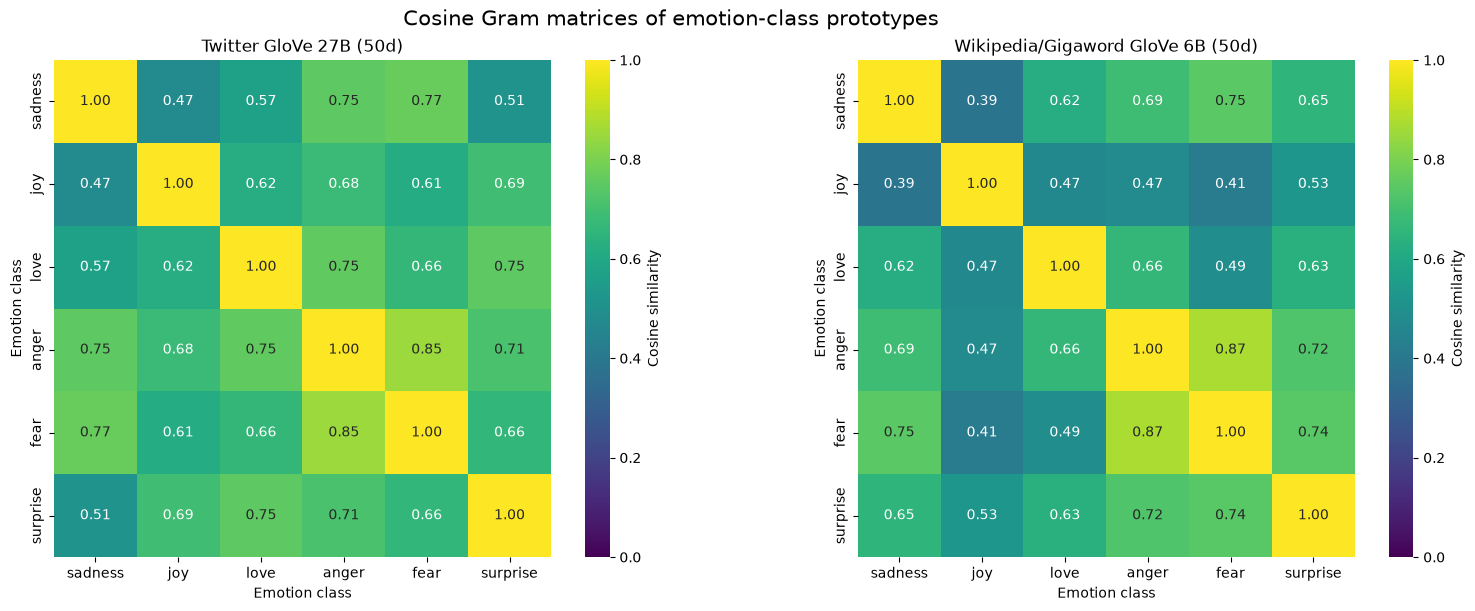

In [104]:
import seaborn as sns

class_names = list(informative_words)
common_words = set.intersection(
    *(set(vectors) for vectors in selected_vectors_by_model.values())
)

words_used_by_class = {
    class_name: [
        word for word in informative_words[class_name]
        if word in common_words
    ]
    for class_name in class_names
}

if any(not words for words in words_used_by_class.values()):
    raise ValueError("At least one class has no words shared by both embedding models.")

gram_matrices = {}
class_prototypes = {}

for model_name, vectors in selected_vectors_by_model.items():
    prototypes = np.stack([
        np.mean(
            [vectors[word] for word in words_used_by_class[class_name]],
            axis=0,
        )
        for class_name in class_names
    ])
    normalized_prototypes = prototypes / np.clip(
        np.linalg.norm(prototypes, axis=1, keepdims=True), 1e-12, None
    )
    class_prototypes[model_name] = normalized_prototypes
    gram_matrices[model_name] = normalized_prototypes @ normalized_prototypes.T

for model_name, gram in gram_matrices.items():
    save_table(pd.DataFrame(gram, index=class_names, columns=class_names), f"gram_matrix_{model_name}_{shared_glove_dim}d")

display(pd.DataFrame(words_used_by_class).T.rename(columns=lambda i: f"word_{i + 1}"))

fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
plot_titles = {
    "glove_twitter": f"Twitter GloVe 27B ({shared_glove_dim}d)",
    "glove_6B": f"Wikipedia/Gigaword GloVe 6B ({shared_glove_dim}d)",
}

for axis, model_name in zip(axes, embedding_candidates):
    gram_df = pd.DataFrame(
        gram_matrices[model_name], index=class_names, columns=class_names
    )
    sns.heatmap(
        gram_df,
        annot=True,
        fmt=".2f",
        cmap="viridis",
        vmin=0,
        vmax=1,
        square=True,
        ax=axis,
        cbar_kws={"label": "Cosine similarity"},
    )
    axis.set_title(plot_titles.get(model_name, model_name))
    axis.set_xlabel("Emotion class")
    axis.set_ylabel("Emotion class")

fig.suptitle("Cosine Gram matrices of emotion-class prototypes", fontsize=15)
plt.show()

In [105]:
# Summarize the strongest and weakest off-diagonal class relationships.
relationship_rows = []
for model_name, gram in gram_matrices.items():
    for i in range(len(class_names)):
        for j in range(i + 1, len(class_names)):
            relationship_rows.append({
                "model": model_name,
                "class_a": class_names[i],
                "class_b": class_names[j],
                "cosine_similarity": gram[i, j],
            })

relationship_df = pd.DataFrame(relationship_rows)
save_table(relationship_df, f"class_relationships_{shared_glove_dim}d", index=False)
for model_name in embedding_candidates:
    model_relationships = relationship_df[
        relationship_df["model"] == model_name
    ].sort_values("cosine_similarity", ascending=False)

    print(f"\n{model_name}")
    print("Most similar class pairs:")
    display(model_relationships.head(3))
    print("Least similar class pairs:")
    display(model_relationships.tail(3).sort_values("cosine_similarity"))


glove_twitter
Most similar class pairs:


,model,class_a,class_b,cosine_similarity
12,glove_twitter,anger,fear,0.849688
3,glove_twitter,sadness,fear,0.768188
9,glove_twitter,love,anger,0.754745


Least similar class pairs:


,model,class_a,class_b,cosine_similarity
0,glove_twitter,sadness,joy,0.473992
4,glove_twitter,sadness,surprise,0.512259
1,glove_twitter,sadness,love,0.570900



glove_6B
Most similar class pairs:


,model,class_a,class_b,cosine_similarity
27,glove_6B,anger,fear,0.871410
18,glove_6B,sadness,fear,0.745940
29,glove_6B,fear,surprise,0.739605


Least similar class pairs:


,model,class_a,class_b,cosine_similarity
15,glove_6B,sadness,joy,0.385432
22,glove_6B,joy,fear,0.413208
20,glove_6B,joy,love,0.466701


## Interpretation

Both embedding models contain all 30 informative words, so every prototype is based on the same five words. Inspect the generated relationship tables for the cosine values at the currently selected `shared_glove_dim`. If anger–fear and sadness–fear are among the strongest relationships, this is plausible because these are negative emotions that occur in related situations and linguistic contexts. Their proximity may also help explain why a model based on pooled embeddings could struggle to distinguish these labels.

Likewise, a low sadness–joy similarity matches the intuitive contrast between these emotions. Agreement between the two models in the ordering of important relationships is evidence that both spaces capture task-relevant emotion structure.

Because both models use the same configured dimensionality, dimensionality is controlled and differences in the matrices are more directly attributable to their training corpora and learned geometry. Higher similarity does not by itself mean that an embedding is a better classifier representation: a model may encode related emotions closely while making them harder to distinguish. Downstream cross-validation is therefore still necessary to decide which representation works better.

The matrices are a diagnostic rather than a direct classification score. The informative words were selected for their predictive weights, not because they are perfect dictionary definitions of each emotion. For example, the Project 1 joy list contains `superior`, `divine`, `sincere`, `valued`, and `convinced`; this helps explain why some relationships involving joy may differ from intuition. Furthermore, GloVe learns from co-occurrence, so antonyms and contrasting emotions can be similar when they appear in comparable contexts.

# Embed-and-pool experiment

Following the Part 2 tutorial, an embed-and-pool encoder maps each token ID to its pretrained vector and averages or sums the vectors along the sequence dimension. The resulting fixed-dimensional document vector is passed to a two-hidden-layer softmax regressor. This is a continuous bag-of-words model: it uses dense word representations but discards word order.

We conduct a controlled comparison with one shared embedding dimensionality and identical data folds, tokenizer, classifier architecture, and optimization settings. The systems test: (1) Twitter versus Wikipedia/Gigaword pretraining, (2) mean versus sum pooling, (3) frozen versus trainable pretrained embeddings, and (4) pretrained versus randomly initialized trainable embeddings. The random baseline is important because it tests whether pretrained vectors add information beyond the architecture and vocabulary.

## Corpus-restricted embedding tables

The original GloVe files are very large. For efficiency, we retain only vectors for words observed in the training corpus. This does not discard any vector that the classifier can use. Each model receives a zero padding vector and an unknown vector equal to the mean of its retained pretrained vectors, matching the strategy in `part2.clslib.PretrainedEmbeddings`.

In [106]:
import copy
import random

import torch
from sklearn.metrics import f1_score

import part2


class CorpusEmbeddings:
    """Minimal embedding-model interface expected by part2.experiment."""

    def __init__(self, vocab, vectors, pad_token="<pad>", unk_token="<unk>"):
        self.vocab = vocab
        self.vectors = vectors
        self.pad_token = pad_token
        self.unk_token = unk_token


def load_corpus_embeddings(embedding_path, embedding_dim, required_words):
    pad_token, unk_token = "<pad>", "<unk>"
    vocab = part2.clslib.Vocabulary(
        [pad_token, unk_token], default=unk_token
    )
    vectors = [
        np.zeros(embedding_dim, dtype=np.float32),
        np.zeros(embedding_dim, dtype=np.float32),
    ]
    required_words = set(required_words)

    with open(embedding_path, encoding="utf8") as embedding_file:
        for line in embedding_file:
            parts = line.rstrip().split()
            if len(parts) != embedding_dim + 1:
                continue
            word = parts[0].lower()
            if word in required_words and word not in vocab:
                vocab.add(word)
                vectors.append(np.asarray(parts[1:], dtype=np.float32))

    vectors = np.stack(vectors)
    vectors[vocab.default_index] = vectors[2:].mean(axis=0)
    vocab.freeze()
    return CorpusEmbeddings(vocab, vectors, pad_token, unk_token)


# We preserve stopwords because negation and intensifiers can be useful for emotion.
surface_tokenizer = part2.clslib.BasicTokenizer(
    lowercase=True,
    remove_punct=True,
    remove_stopwords=False,
    language="english",
    vocab=None,
)
corpus_words = {
    word
    for text in train_texts
    for word in surface_tokenizer.tokens(text)
}

corpus_embedding_models = {
    name: load_corpus_embeddings(path, dimension, corpus_words)
    for name, (path, dimension) in embedding_candidates.items()
}

for name, model in corpus_embedding_models.items():
    print(
        f"{name}: vectors={model.vectors.shape}, "
        f"corpus vocabulary coverage={len(model.vocab) - 2:,}/{len(corpus_words):,}"
    )

glove_twitter: vectors=(15183, 50), corpus vocabulary coverage=15,181/16,194
glove_6B: vectors=(15093, 50), corpus vocabulary coverage=15,091/16,194


In [107]:
def make_random_embedding_model(reference_model, seed=0):
    """Random table with the same vocabulary, shape and scale as a reference."""
    rng = np.random.default_rng(seed)
    scale = reference_model.vectors[2:].std()
    vectors = rng.normal(
        loc=0.0, scale=scale, size=reference_model.vectors.shape
    ).astype(np.float32)
    vectors[reference_model.vocab.index(reference_model.pad_token)] = 0.0
    return CorpusEmbeddings(
        reference_model.vocab,
        vectors,
        reference_model.pad_token,
        reference_model.unk_token,
    )

random_embedding_model = make_random_embedding_model(
    corpus_embedding_models["glove_twitter"], seed=0
)

## Experimental design

The default experiment uses three folds and one predefined split seed as a computationally manageable first pass. Increase `embed_pool_seeds` to `[0, 3, 5]` and preferably use five folds for the final reported experiment. All systems within a run use the same folds. We select the best epoch by validation loss, as in the tutorial, and report both accuracy and macro-F1; macro-F1 is primary because the emotion labels are imbalanced.

In [108]:
from collections import OrderedDict

embed_pool_seeds = [0]
embed_pool_num_folds = 3
embed_pool_device = (
    "mps" if torch.backends.mps.is_available() else "cpu"
)
embed_pool_results_folder = Path("results/embed-and-pool-project2")
embed_pool_results_folder.mkdir(parents=True, exist_ok=True)

embed_pool_splits = [
    part1.experiment.cross_validation_split(
        list(zip(dataset["train"]["text"], dataset["train"]["label"])),
        k=embed_pool_num_folds,
        seed=seed,
    )
    for seed in embed_pool_seeds
]

embed_pool_configs = OrderedDict({
    "twitter_mean_frozen": {
        "embedding_model": corpus_embedding_models["glove_twitter"],
        "average_pool": True,
        "freeze_embeddings": True,
    },
    "glove6B_mean_frozen": {
        "embedding_model": corpus_embedding_models["glove_6B"],
        "average_pool": True,
        "freeze_embeddings": True,
    },

    "twitter_mean_trainable": {
        "embedding_model": corpus_embedding_models["glove_twitter"],
        "average_pool": True,
        "freeze_embeddings": False,
    },
    "glove6B_mean_trainable": {
        "embedding_model": corpus_embedding_models["glove_6B"],
        "average_pool": True,
        "freeze_embeddings": False,
    },
    "random_mean_trainable": {
        "embedding_model": random_embedding_model,
        "average_pool": True,
        "freeze_embeddings": False,
    },
})

common_regressor_kwargs = {
    "hidden_size1": 64,
    "hidden_size2": 64,
    "dropout": 0.2,
}
common_optimizer_kwargs = {
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "batch_size": 128,
    "num_epochs": 15,
}

print(f"Device: {embed_pool_device}")
print(f"Systems: {list(embed_pool_configs)}")
print(
    f"Measurements per system: "
    f"{len(embed_pool_seeds) * embed_pool_num_folds}"
)

Device: mps
Systems: ['twitter_mean_frozen', 'glove6B_mean_frozen', 'twitter_mean_trainable', 'glove6B_mean_trainable', 'random_mean_trainable']
Measurements per system: 3


In [109]:
def run_embed_pool_experiment():
    embed_pool_classifiers = OrderedDict()

    for system_name, config in embed_pool_configs.items():
        print(f"\n===== {system_name} =====")
        embed_pool_classifiers[system_name] = []

        embedding_model = config["embedding_model"]
        model_tokenizer = part2.clslib.BasicTokenizer(
            lowercase=True,
            remove_punct=True,
            remove_stopwords=False,
            language="english",
            vocab=embedding_model.vocab,
        )

        for run, seed in enumerate(embed_pool_seeds):
            # Deterministic initialization and minibatch order for reproducibility.
            experiment_seed = seed
            random.seed(experiment_seed)
            np.random.seed(experiment_seed)
            torch.manual_seed(experiment_seed)

            run_folder = (
                embed_pool_results_folder / system_name / f"seed-{seed}"
            )
            run_result = part2.experiment.cross_validation(
                outcome_space=outcome_space,
                data_splits=embed_pool_splits[run],
                tokenizer=model_tokenizer,
                emb_model=embedding_model,
                enc_type="embed-and-pool",
                enc_kwargs={
                    "average_pool": config["average_pool"],
                    "freeze_embeddings": config["freeze_embeddings"],
                },
                regressor_kwargs=dict(common_regressor_kwargs),
                opt_kwargs=dict(common_optimizer_kwargs),
                device=embed_pool_device,
                save_to=run_folder,
            )

            run_result["macro_f1_scores"] = OrderedDict()
            for fold, predictions in run_result["predictions"].items():
                gold = [
                    label
                    for _, label in embed_pool_splits[run][fold]["validation"]
                ]
                run_result["macro_f1_scores"][fold] = f1_score(
                    gold, predictions, average="macro", zero_division=0
                )

            embed_pool_classifiers[system_name].append(run_result)
    return embed_pool_classifiers


embed_pool_classifiers = load_or_compute(
    "embed_pool_classifiers",
    run_embed_pool_experiment,
    key={
        "systems": {
            name: {k: v for k, v in config.items() if k != "embedding_model"}
            for name, config in embed_pool_configs.items()
        },
        "regressor": common_regressor_kwargs,
        "optimizer": common_optimizer_kwargs,
        "seeds": embed_pool_seeds,
        "folds": embed_pool_num_folds,
        "glove_dim": shared_glove_dim,
        "class_weighted_loss": True,
    },
)


===== twitter_mean_frozen =====


  0%|          | 0/3 [00:00<?, ?it/s]

Tokenizing texts...
Tokenization done! Time taken: 1.128 seconds
Dataloader done! Time taken: 0.022 seconds


  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.5920 | train acc: 0.3578 | val loss: 1.5056 | val acc: 0.4515
Epoch 02 | train loss: 1.4873 | train acc: 0.4298 | val loss: 1.3911 | val acc: 0.4793
Epoch 03 | train loss: 1.4424 | train acc: 0.4415 | val loss: 1.3669 | val acc: 0.4813
Epoch 04 | train loss: 1.4303 | train acc: 0.4457 | val loss: 1.3533 | val acc: 0.4852
Epoch 05 | train loss: 1.4127 | train acc: 0.4497 | val loss: 1.3317 | val acc: 0.4938
Epoch 06 | train loss: 1.4070 | train acc: 0.4510 | val loss: 1.3208 | val acc: 0.4908
Epoch 07 | train loss: 1.3969 | train acc: 0.4565 | val loss: 1.3253 | val acc: 0.4982
Epoch 08 | train loss: 1.3939 | train acc: 0.4552 | val loss: 1.3024 | val acc: 0.5033
Epoch 09 | train loss: 1.3889 | train acc: 0.4571 | val loss: 1.3058 | val acc: 0.4992
Epoch 10 | train loss: 1.3895 | train acc: 0.4522 | val loss: 1.3015 | val acc: 0.5027
Epoch 11 | train loss: 1.3935 | train acc: 0.4510 | val loss: 1.3016 | val acc: 0.4995
Epoch 12 | train loss: 1.3836 | train acc: 

  0%|          | 0/15 [00:00<?, ?it/s]

... (31 outputs left out)

  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.6059 | train acc: 0.3245 | val loss: 1.5688 | val acc: 0.3628
Epoch 02 | train loss: 1.5386 | train acc: 0.3805 | val loss: 1.5159 | val acc: 0.4013
Epoch 03 | train loss: 1.4529 | train acc: 0.4393 | val loss: 1.4053 | val acc: 0.4592
Epoch 04 | train loss: 1.3124 | train acc: 0.5076 | val loss: 1.2705 | val acc: 0.5252
Epoch 05 | train loss: 1.1652 | train acc: 0.5723 | val loss: 1.1502 | val acc: 0.5728
Epoch 06 | train loss: 1.0334 | train acc: 0.6229 | val loss: 1.0286 | val acc: 0.6202
Epoch 07 | train loss: 0.9095 | train acc: 0.6716 | val loss: 0.9390 | val acc: 0.6563
Epoch 08 | train loss: 0.8091 | train acc: 0.7067 | val loss: 0.8682 | val acc: 0.6837
Epoch 09 | train loss: 0.7273 | train acc: 0.7408 | val loss: 0.8130 | val acc: 0.7080
Epoch 10 | train loss: 0.6498 | train acc: 0.7635 | val loss: 0.7717 | val acc: 0.7240
Epoch 11 | train loss: 0.5839 | train acc: 0.7923 | val loss: 0.7302 | val acc: 0.7413
Epoch 12 | train loss: 0.5327 | train acc: 

  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.6100 | train acc: 0.3268 | val loss: 1.5632 | val acc: 0.3392
Epoch 02 | train loss: 1.5469 | train acc: 0.3644 | val loss: 1.5249 | val acc: 0.3855
Epoch 03 | train loss: 1.4796 | train acc: 0.4050 | val loss: 1.4289 | val acc: 0.4380
Epoch 04 | train loss: 1.3496 | train acc: 0.4764 | val loss: 1.2910 | val acc: 0.5030
Epoch 05 | train loss: 1.1893 | train acc: 0.5430 | val loss: 1.1487 | val acc: 0.5620
Epoch 06 | train loss: 1.0397 | train acc: 0.6143 | val loss: 1.0257 | val acc: 0.6133
Epoch 07 | train loss: 0.9076 | train acc: 0.6635 | val loss: 0.9278 | val acc: 0.6568
Epoch 08 | train loss: 0.7929 | train acc: 0.7073 | val loss: 0.8451 | val acc: 0.6918
Epoch 09 | train loss: 0.7065 | train acc: 0.7408 | val loss: 0.7843 | val acc: 0.7167
Epoch 10 | train loss: 0.6250 | train acc: 0.7738 | val loss: 0.7348 | val acc: 0.7347
Epoch 11 | train loss: 0.5473 | train acc: 0.8041 | val loss: 0.7000 | val acc: 0.7485
Epoch 12 | train loss: 0.5028 | train acc: 

## Embed-and-pool results

Each point below is one validation-fold measurement. With only one split seed and three folds, these results are preliminary; the final comparison should use more runs and folds.

accuracy                  macro_f1                
                            mean       std count      mean       std count
model                                                                     
twitter_mean_trainable  0.814778  0.004141     3  0.743983  0.005641     3
glove6B_mean_trainable  0.807222  0.001678     3  0.726844  0.007282     3
random_mean_trainable   0.788056  0.007804     3  0.696144  0.018551     3
twitter_mean_frozen     0.492333  0.012956     3  0.258911  0.013709     3
glove6B_mean_frozen     0.491000  0.008368     3  0.251511  0.011473     3

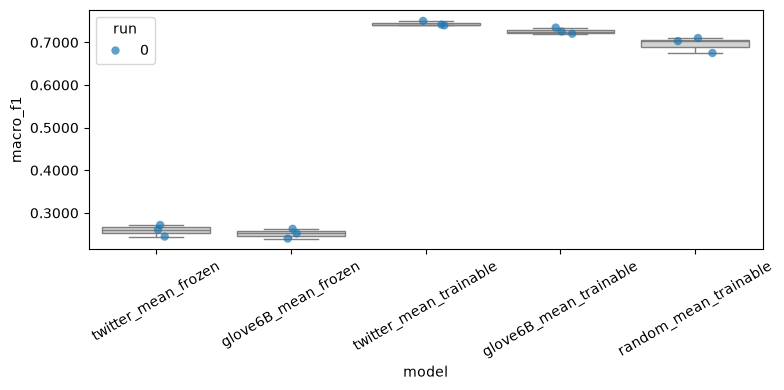

In [110]:
embed_pool_results_df = part1.analysis.make_data_frame(
    embed_pool_classifiers
)
embed_pool_summary = (
    embed_pool_results_df
    .groupby("model")[["accuracy", "macro_f1"]]
    .agg(["mean", "std", "count"])
    .sort_values(("macro_f1", "mean"), ascending=False)
)
save_table(embed_pool_results_df, "embed_pool_scores", index=False)
save_table(embed_pool_summary, "embed_pool_summary")
display(embed_pool_summary)
part1.analysis.plot_box_and_points(
    embed_pool_results_df, metric="macro_f1"
)

In [111]:
# Paired fold differences for the controlled research questions.
paired_questions = [
    ("Twitter vs GloVe 6B (frozen mean)",
     "twitter_mean_frozen", "glove6B_mean_frozen"),
    ("Mean vs sum pooling (frozen Twitter)",
     "twitter_mean_frozen", "twitter_sum_frozen"),
    ("Fine-tuned vs frozen Twitter",
     "twitter_mean_trainable", "twitter_mean_frozen"),
    ("Twitter vs GloVe 6B (trainable mean)",
     "twitter_mean_trainable", "glove6B_mean_trainable"),
    ("Pretrained vs random trainable embeddings",
     "twitter_mean_trainable", "random_mean_trainable"),
]

comparison_rows = []
skipped_comparisons = []
expected_pairs = len(embed_pool_seeds) * embed_pool_num_folds
for question, system_a, system_b in paired_questions:
    scores_a = (
        embed_pool_results_df[embed_pool_results_df["model"] == system_a]
        .set_index(["run", "fold"])["macro_f1"]
        .rename("A")
    )
    scores_b = (
        embed_pool_results_df[embed_pool_results_df["model"] == system_b]
        .set_index(["run", "fold"])["macro_f1"]
        .rename("B")
    )
    paired_scores = pd.concat([scores_a, scores_b], axis=1, join="inner").dropna()

    if len(paired_scores) != expected_pairs:
        skipped_comparisons.append({
            "question": question,
            "A": system_a,
            "A_measurements": len(scores_a),
            "B": system_b,
            "B_measurements": len(scores_b),
            "paired_measurements": len(paired_scores),
            "required_measurements": expected_pairs,
            "status": "skipped: missing or incomplete results",
        })
        continue

    differences = (paired_scores["A"] - paired_scores["B"]).to_numpy()
    comparison_rows.append({
        "question": question,
        "A": system_a,
        "B": system_b,
        "mean_macro_f1_A_minus_B": differences.mean(),
        "std_difference": differences.std(ddof=1),
        "A_wins": int(np.sum(differences > 0)),
        "B_wins": int(np.sum(differences < 0)),
        "ties": int(np.sum(differences == 0)),
    })

paired_embed_pool_comparisons = pd.DataFrame(comparison_rows)
if not paired_embed_pool_comparisons.empty:
    paired_embed_pool_comparisons = paired_embed_pool_comparisons.set_index("question")
    save_table(paired_embed_pool_comparisons, "embed_pool_paired_comparisons")
    display(paired_embed_pool_comparisons)

skipped_embed_pool_comparisons = pd.DataFrame(skipped_comparisons)
if not skipped_embed_pool_comparisons.empty:
    print("Skipped comparisons (run the missing systems to enable them):")
    display(skipped_embed_pool_comparisons.set_index("question"))

,A,B,mean_macro_f1_A_minus_B,std_difference,A_wins,B_wins,ties
question,,,,,,,
Twitter vs GloVe 6B (frozen mean),twitter_mean_frozen,glove6B_mean_frozen,0.007399,0.011274,2,1,0
Fine-tuned vs frozen Twitter,twitter_mean_trainable,twitter_mean_frozen,0.485072,0.015051,3,0,0
Twitter vs GloVe 6B (trainable mean),twitter_mean_trainable,glove6B_mean_trainable,0.017139,0.003603,3,0,0
Pretrained vs random trainable embeddings,twitter_mean_trainable,random_mean_trainable,0.047839,0.016161,3,0,0


Skipped comparisons (run the missing systems to enable them):


,A,A_measurements,B,B_measurements,paired_measurements,required_measurements,status
question,,,,,,,
Mean vs sum pooling (frozen Twitter),twitter_mean_frozen,3,twitter_sum_frozen,0,0,3,skipped: missing or incomplete results


## Embed-and-pool interpretation

In the current saved preliminary run (`shared_glove_dim = 50`), the frozen Twitter and GloVe 6B models are effectively tied: their mean macro-F1 scores are 0.240 and 0.237. Mean pooling is slightly better than sum pooling (paired difference about +0.007 macro-F1), but the effect is small.

Allowing the Twitter embeddings to be updated has the largest effect: macro-F1 rises from 0.240 to 0.598. When both pretrained sources are trainable, Twitter GloVe also outperforms GloVe 6B (0.598 versus 0.561 macro-F1). The paired mean advantage is +0.0369, and Twitter wins all three folds. This provides preliminary task-specific evidence that the domain-matched Twitter initialization adapts better to emotion classification than the generic Wikipedia/Gigaword initialization.

The trainable Twitter model also outperforms the randomly initialized trainable model (0.598 versus 0.531), providing evidence that pretraining adds useful information beyond the architecture and vocabulary. However, this is only a three-fold, one-seed first pass. The final claim should be based on the expanded multi-seed experiment and a paired uncertainty analysis.

In [72]:
# Intentionally left available for follow-up analyses.

# Hyperparameter optimization for Twitter GloVe

The preliminary comparison selected trainable Twitter GloVe with mean pooling. We now optimize the remaining design choices without touching the held-out test set.

**Search protocol.**
* **Objective:** every trial is scored by its *mean macro-F1 over all three folds* of the tuning split (split seed 0), not on a single fold, which makes the objective less noisy and harder to overfit.
* **Budget:** 60 trials (TPE sampler with 10 random start-up trials), early stopping inside each fold, and median pruning after each fold, so clearly weak configurations stop after one or two folds.
* **Search space:** embedding dimensionality (50/100/200), widths of both hidden layers (16–128), dropout (0–0.5), learning rate (2e-4–1e-2, log scale), weight decay (1e-6–1e-3, log scale) and batch size (64/128/256). The ranges were widened after a first small search placed the best learning rate and hidden sizes on the boundary of the original ranges.
* **Persistence:** the study is stored in `results/optuna.db`, so results survive kernel restarts and re-running the cell resumes the search instead of starting over.

Mean pooling and trainable Twitter embeddings remain fixed because the earlier controlled experiment selected them.

In [ ]:
import gc

import optuna
import torch.nn as nn
from torch.utils.data import DataLoader

OPTUNA_SEED = 17
OPTUNA_TRIALS = 60               # total trials in the study (the search resumes up to this number)
OPTUNA_TIMEOUT_SECONDS = 3600    # safety cap for one call of study.optimize
OPTUNA_MAX_EPOCHS = 10
OPTUNA_PATIENCE = 3
OPTUNA_STUDY_NAME = f"embed-pool-twitter-3fold-class-weighted-{DATA_VERSION}"
OPTUNA_STORAGE = "sqlite:///results/optuna.db"
twitter_embedding_dimensions = [50, 100, 200]

# Tuning uses the split-seed-0 folds; the confirmation later uses different split seeds.
tuning_splits = embed_pool_splits[0]
tuning_folds = list(tuning_splits.keys())

# Load each corpus-restricted table once; trials reuse these arrays.
twitter_embeddings_by_dim = {}
for dimension in twitter_embedding_dimensions:
    if dimension == shared_glove_dim:
        model = corpus_embedding_models["glove_twitter"]
    else:
        path = (
            glove_root / "glove.twitter.27B"
            / f"glove.twitter.27B.{dimension}d.txt"
        )
        model = load_corpus_embeddings(path, dimension, corpus_words)
    twitter_embeddings_by_dim[dimension] = model
    print(f"Twitter GloVe {dimension}d: {model.vectors.shape}")


def make_tokenizer(embedding_model):
    return part2.clslib.BasicTokenizer(
        lowercase=True, remove_punct=True, remove_stopwords=False,
        language="english", vocab=embedding_model.vocab,
    )


# Cache tokenized datasets per (dimension, fold) so trials never re-tokenize.
tuning_data_by_dim = {}
for dimension, embedding_model in twitter_embeddings_by_dim.items():
    tuning_tokenizer = make_tokenizer(embedding_model)
    pad_id = embedding_model.vocab.index(embedding_model.pad_token)
    tuning_data_by_dim[dimension] = {}
    for fold in tuning_folds:
        fold_data = {}
        for part in ("training", "validation"):
            pairs = tuning_splits[fold][part]
            fold_data[part] = part2.experiment.LabelledCorpus(
                [tuning_tokenizer.ids(text) for text, _ in pairs],
                [int(label) for _, label in pairs],
            )
        fold_data["pad_id"] = pad_id
        tuning_data_by_dim[dimension][fold] = fold_data

print(
    f"Tuning split: {len(tuning_folds)} folds of "
    f"{len(tuning_splits[0]['training']):,} training and "
    f"{len(tuning_splits[0]['validation']):,} validation examples"
)

In [113]:
def train_fold(params, fold_data, seed=OPTUNA_SEED):
    """Train one embed-and-pool model on one fold; return its best validation macro-F1 and epoch."""
    pad_id = fold_data["pad_id"]
    embedding_model = twitter_embeddings_by_dim[params["embedding_dim"]]

    # Same initialization/minibatch seed in every trial, so trials differ only by hyperparameters.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    generator = torch.Generator().manual_seed(seed)

    collate = lambda batch: part2.experiment.collate_labelled_texts(batch, padding_value=pad_id)
    train_loader = DataLoader(
        fold_data["training"], batch_size=params["batch_size"], shuffle=True,
        generator=generator, collate_fn=collate,
    )
    validation_loader = DataLoader(
        fold_data["validation"], batch_size=params["batch_size"], shuffle=False,
        collate_fn=collate,
    )

    encoder = part2.clslib.EmbedAndPoolEncoder(
        embedding_matrix=torch.tensor(embedding_model.vectors, dtype=torch.float32),
        average_pool=True, freeze_embeddings=False, padding_idx=pad_id,
    )
    model = part2.clslib.SoftmaxRegressor(
        hidden_size1=params["hidden_size1"], hidden_size2=params["hidden_size2"],
        num_classes=len(outcome_space), encoder=encoder, dropout=params["dropout"],
    ).to(embed_pool_device)
    criterion = part2.experiment.class_weighted_nll_loss(
        fold_data["training"].y, len(outcome_space), embed_pool_device
    )
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=params["learning_rate"], weight_decay=params["weight_decay"]
    )

    best_macro_f1, best_epoch, epochs_without_improvement = -np.inf, -1, 0
    try:
        for epoch in range(OPTUNA_MAX_EPOCHS):
            part2.experiment.training_one_epoch(
                model, train_loader, optimizer, criterion, embed_pool_device
            )
            validation_metrics = part2.experiment.evaluate(
                model, validation_loader, criterion, embed_pool_device
            )
            predictions = np.asarray(
                [p for batch in validation_metrics["predictions"] for p in batch]
            )
            labels = np.asarray(
                [y for batch in validation_metrics["labels"] for y in batch]
            )
            macro_f1 = f1_score(labels, predictions, average="macro", zero_division=0)

            if macro_f1 > best_macro_f1 + 1e-4:
                best_macro_f1, best_epoch, epochs_without_improvement = macro_f1, epoch, 0
            else:
                epochs_without_improvement += 1
            if epochs_without_improvement >= OPTUNA_PATIENCE:
                break
        return float(best_macro_f1), best_epoch + 1
    finally:
        del model, encoder, optimizer, train_loader, validation_loader
        gc.collect()
        if torch.backends.mps.is_available():
            torch.mps.empty_cache()


def optuna_embed_pool_objective(trial):
    params = {
        "embedding_dim": trial.suggest_categorical("embedding_dim", [50, 100, 200]),
        "hidden_size1": trial.suggest_categorical("hidden_size1", [16, 32, 64, 128]),
        "hidden_size2": trial.suggest_categorical("hidden_size2", [16, 32, 64, 128]),
        "dropout": trial.suggest_float("dropout", 0.0, 0.5, step=0.1),
        "learning_rate": trial.suggest_float("learning_rate", 2e-4, 1e-2, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [64, 128, 256]),
    }

    fold_scores, fold_epochs = [], []
    for step, fold in enumerate(tuning_folds):
        score, epoch = train_fold(params, tuning_data_by_dim[params["embedding_dim"]][fold])
        fold_scores.append(score)
        fold_epochs.append(epoch)
        # Report the running mean after each fold so the pruner can stop weak trials early.
        trial.report(float(np.mean(fold_scores)), step=step)
        if trial.should_prune():
            raise optuna.TrialPruned()

    trial.set_user_attr("fold_macro_f1", [round(s, 4) for s in fold_scores])
    trial.set_user_attr("fold_macro_f1_std", float(np.std(fold_scores, ddof=1)))
    trial.set_user_attr("best_epochs", fold_epochs)
    return float(np.mean(fold_scores))

In [114]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
Path("results").mkdir(exist_ok=True)

study = optuna.create_study(
    study_name=OPTUNA_STUDY_NAME,
    storage=OPTUNA_STORAGE,
    load_if_exists=True,   # re-running this cell resumes the stored study
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=OPTUNA_SEED, n_startup_trials=10, multivariate=True
    ),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=0),
)

finished_states = (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED)
remaining_trials = OPTUNA_TRIALS - len(study.get_trials(states=finished_states))
if remaining_trials > 0:
    study.optimize(
        optuna_embed_pool_objective,
        n_trials=remaining_trials,
        timeout=OPTUNA_TIMEOUT_SECONDS,
        n_jobs=1,
        gc_after_trial=True,
        show_progress_bar=True,
    )

n_complete = len(study.get_trials(states=(optuna.trial.TrialState.COMPLETE,)))
n_pruned = len(study.get_trials(states=(optuna.trial.TrialState.PRUNED,)))
print(f"Trials: {n_complete} complete, {n_pruned} pruned")
print(f"Best 3-fold mean macro-F1 (tuning split): {study.best_value:.4f}")
print(f"Per-fold macro-F1: {study.best_trial.user_attrs.get('fold_macro_f1')}")
print(f"Best epochs per fold: {study.best_trial.user_attrs.get('best_epochs')}")
print("Best parameters:")
best_params_df = pd.Series(study.best_params, name="value").to_frame()
save_table(best_params_df, "optuna_best_params")
display(best_params_df)
# The best parameters can be reloaded later without re-running the search:
# optuna.load_study(study_name=OPTUNA_STUDY_NAME, storage=OPTUNA_STORAGE).best_params

  0%|          | 0/60 [00:00<?, ?it/s]

[W 2026-11-18 19:33:57,140] Trial 1 failed with parameters: {'embedding_dim': 50, 'hidden_size1': 128, 'hidden_size2': 16, 'dropout': 0.4, 'learning_rate': 0.0006275790142825236, 'weight_decay': 3.947495254586707e-06, 'batch_size': 64} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/Users/gregory/Documents/uva/period-2/nlp/code/nlp-assignment-1/.venv/lib/python3.14/site-packages/optuna/study/_optimize.py", line 210, in _run_trial
    value_or_values = func(trial)
  File "/var/folders/xv/sdnn3vm12h7f822hg67xpsnm0000gn/T/ipykernel_4299/2728828335.py", line 79, in optuna_embed_pool_objective
    score, epoch = train_fold(params, tuning_data_by_dim[params["embedding_dim"]][fold])
                   ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/folders/xv/sdnn3vm12h7f822hg67xpsnm0000gn/T/ipykernel_4299/2728828335.py", line 41, in train_fold
    validation_metrics = part2.experiment.evaluate(
        model,

KeyboardInterrupt: 

In [ ]:
optuna_trials_df = study.trials_dataframe(
    attrs=("number", "value", "params", "state", "user_attrs")
)
save_table(optuna_trials_df, "optuna_trials", index=False)
display(optuna_trials_df.sort_values("value", ascending=False))

parameter_importance = optuna.importance.get_param_importances(study)
importance_series = pd.Series(parameter_importance).sort_values()
axis = importance_series.plot.barh(figsize=(8, 4), color="steelblue")
axis.set_xlabel("Optuna importance")
axis.set_title("Hyperparameter importance on the tuning fold")
plt.tight_layout()
plt.show()

## Multi-seed confirmation on unseen splits

The tuning score is optimistic because it was used to choose the hyperparameters, and the tuning folds were seen during the search. We therefore re-evaluate the selected configuration on **fresh 3-fold splits created with five different split seeds (1–5)**, which Optuna never saw, giving 15 measurements per system. Each seed also changes weight initialization and minibatch order, so the spread covers both data-split and training variance.

The trainable Twitter baseline from the preliminary comparison (default hyperparameters) is re-run on exactly the same splits, so the comparison is paired (same seed, same fold). The Twitter vs GloVe 6B question was already settled in the preliminary comparison and is not repeated here. We report means with 95% t-intervals, and for paired differences the number of wins and a Wilcoxon signed-rank test. Folds within a seed share training data and are not fully independent, so the intervals should be read as approximate. The original test set remains untouched in this step.

In [ ]:
from scipy import stats

CONFIRM_SEEDS = [1, 2, 3, 4, 5]     # disjoint from the tuning split seed (0)
RUN_BASELINES = True                # set False to confirm only the tuned configuration

train_pairs = list(zip(dataset["train"]["text"], dataset["train"]["label"]))
confirm_splits = {
    seed: part1.experiment.cross_validation_split(train_pairs, k=embed_pool_num_folds, seed=seed)
    for seed in CONFIRM_SEEDS
}

best_params = study.best_params
confirm_systems = OrderedDict()
confirm_systems["optuna_best"] = {
    "embedding_model": twitter_embeddings_by_dim[best_params["embedding_dim"]],
    "regressor_kwargs": {
        "hidden_size1": best_params["hidden_size1"],
        "hidden_size2": best_params["hidden_size2"],
        "dropout": best_params["dropout"],
    },
    "opt_kwargs": {
        "learning_rate": best_params["learning_rate"],
        "weight_decay": best_params["weight_decay"],
        "batch_size": best_params["batch_size"],
        "num_epochs": OPTUNA_MAX_EPOCHS,
    },
}
if RUN_BASELINES:
    confirm_systems["twitter_mean_trainable"] = {
        "embedding_model": corpus_embedding_models["glove_twitter"],
        "regressor_kwargs": common_regressor_kwargs,
        "opt_kwargs": common_optimizer_kwargs,
    }

def run_confirmation():
    confirm_results = OrderedDict()
    confirm_rows = []
    for system_name, config in confirm_systems.items():
        print(f"\n===== {system_name} =====")
        system_tokenizer = make_tokenizer(config["embedding_model"])
        for seed in CONFIRM_SEEDS:
            random.seed(seed)
            np.random.seed(seed)
            torch.manual_seed(seed)
            result = part2.experiment.cross_validation(
                outcome_space=outcome_space,
                data_splits=confirm_splits[seed],
                tokenizer=system_tokenizer,
                emb_model=config["embedding_model"],
                enc_type="embed-and-pool",
                enc_kwargs={"average_pool": True, "freeze_embeddings": False},
                regressor_kwargs=dict(config["regressor_kwargs"]),   # copies: train() mutates them
                opt_kwargs=dict(config["opt_kwargs"]),
                device=embed_pool_device,
                save_to=embed_pool_results_folder / "confirmation" / system_name / f"seed-{seed}",
            )
            confirm_results[(system_name, seed)] = result
            for fold, predictions in result["predictions"].items():
                gold = [label for _, label in confirm_splits[seed][fold]["validation"]]
                confirm_rows.append({
                    "system": system_name, "seed": seed, "fold": fold,
                    "accuracy": result["accuracies"][fold],
                    "macro_f1": f1_score(gold, predictions, average="macro", zero_division=0),
                })
    return confirm_results, confirm_rows


confirm_results, confirm_rows = load_or_compute(
    "confirmation",
    run_confirmation,
    key={
        "systems": {name: {"regressor": c["regressor_kwargs"], "optimizer": c["opt_kwargs"],
                           "embedding_rows": len(c["embedding_model"].vectors),
                           "embedding_dim": c["embedding_model"].vectors.shape[1]}
                    for name, c in confirm_systems.items()},
        "seeds": CONFIRM_SEEDS,
        "folds": embed_pool_num_folds,
        "class_weighted_loss": True,
    },
)
confirm_df = pd.DataFrame(confirm_rows)
save_table(confirm_df, "confirmation_scores", index=False)


def mean_ci(values, confidence=0.95):
    values = np.asarray(values, dtype=float)
    half = stats.t.ppf((1 + confidence) / 2, len(values) - 1) * values.std(ddof=1) / np.sqrt(len(values))
    return values.mean(), values.mean() - half, values.mean() + half


summary_rows = []
for system_name, group in confirm_df.groupby("system", sort=False):
    for metric in ("macro_f1", "accuracy"):
        mean, low, high = mean_ci(group[metric])
        summary_rows.append({"system": system_name, "metric": metric, "n": len(group),
                             "mean": mean, "std": group[metric].std(ddof=1),
                             "ci95_low": low, "ci95_high": high})
print("\nConfirmation results (5 split seeds x 3 folds):")
confirm_summary_df = pd.DataFrame(summary_rows)
save_table(confirm_summary_df, "confirmation_summary", index=False)
display(confirm_summary_df.round(4))

if RUN_BASELINES:
    paired = confirm_df.pivot_table(index=["seed", "fold"], columns="system", values="macro_f1")
    paired_rows = []
    for system_a, system_b in [("optuna_best", "twitter_mean_trainable")]:
        diff = paired[system_a] - paired[system_b]
        mean, low, high = mean_ci(diff)
        paired_rows.append({
            "comparison": f"{system_a} - {system_b}", "n": len(diff),
            "mean_diff": mean, "ci95_low": low, "ci95_high": high,
            "A_wins": int((diff > 0).sum()), "B_wins": int((diff < 0).sum()),
            "wilcoxon_p": stats.wilcoxon(diff).pvalue,
        })
    print("Paired macro-F1 differences:")
    confirm_paired_df = pd.DataFrame(paired_rows)
    save_table(confirm_paired_df, "confirmation_paired_comparisons", index=False)
    display(confirm_paired_df.round(4))

## Optimization interpretation

Read the final claims from the multi-seed confirmation tables above, not from the Optuna output: the tuning score was optimized directly and is expected to be higher than the confirmation mean. A paired difference whose 95% interval excludes zero, with a consistent win count and a small Wilcoxon p-value, is evidence of a real improvement; a difference whose interval straddles zero should be reported as inconclusive.

The search is bounded (60 trials over a seven-dimensional space), so its best configuration is the strongest one found within this budget rather than a guaranteed global optimum. The Optuna importance plot indicates which hyperparameters mattered most and therefore where a further search would be most useful.

## Held-out test evaluation

All design and hyperparameter decisions above were made on training-data folds only. As a final step, every model trained in the confirmation is evaluated **once** on the original test set; we report the mean and spread over the 15 models per system. The test results are not used to change any choice.

In [ ]:
test_texts = list(dataset["test"]["text"])
test_labels = np.asarray(dataset["test"]["label"], dtype=int)

test_rows = []
for (system_name, seed), result in confirm_results.items():
    embedding_model = confirm_systems[system_name]["embedding_model"]
    system_tokenizer = make_tokenizer(embedding_model)
    for fold, model_path in result["models"].items():
        trained = part2.experiment.load(model_path, embedding_model, device=embed_pool_device)
        logprobs = part2.experiment.predict_logprobs(
            trained, system_tokenizer, test_texts, 256, embed_pool_device
        )
        predictions = logprobs.argmax(-1)
        test_rows.append({
            "system": system_name, "seed": seed, "fold": fold,
            "accuracy": float((predictions == test_labels).mean()),
            "macro_f1": f1_score(test_labels, predictions, average="macro", zero_division=0),
        })
        del trained

test_df = pd.DataFrame(test_rows)
save_table(test_df, "embed_pool_test_scores", index=False)
display(
    test_df.groupby("system", sort=False)[["macro_f1", "accuracy"]]
    .agg(["mean", "std", "count"]).round(4)
)

# Get to Work 4: Recurrent encoder (LSTM)

We now replace embed-and-pool with a recurrent encoder, `part2.clslib.LSTMEncoder2`. It generalises the tutorial's `LSTMEncoder` with two architectural options:

* `num_layers`: the number of stacked LSTM layers (with `layer_dropout` between layers);
* `bidirectional`: the text is also read right-to-left, and the encoding concatenates the top layer's final forward and backward states, so the encoder output has `2 * hidden_size` dimensions.

With `num_layers=1, bidirectional=False` it is numerically identical to `LSTMEncoder`. Models are trained through `part2.experiment` with `enc_type="lstm2"`.

**Experimental design.** All systems use the 50d Twitter GloVe table, the same tokenizer as embed-and-pool, and the same optimisation settings. They are trained on identical 3-fold splits for three split seeds (9 paired measurements per system); split seed 0 is the same split used for the embed-and-pool comparison. Each controlled comparison changes exactly one factor. Depth is only tested for the bidirectional model, because short texts (about 19 words) give little reason to expect large gains from stacking; the effect of word dropout is studied with learning curves rather than a separate cross-validated system.

| Question | System A | System B |
|---|---|---|
| Does reading in both directions help? | `lstm_bi_l1` | `lstm_uni_l1` |
| Does a second layer help? | `lstm_bi_l2` | `lstm_bi_l1` |
| Should embeddings be fine-tuned? | `lstm_bi_l1` | `lstm_bi_l1_frozen` |
| Does an LSTM beat embed-and-pool? | best LSTM | `embed_pool_reference` |

The embed-and-pool reference is re-trained on the same splits so that the final comparison is paired. Packed LSTMs run considerably faster on the CPU than on MPS for these small models, so this section uses the CPU.

In [ ]:
import importlib
from scipy import stats

# Pick up LSTMEncoder2 / enc_type="lstm2" if the kernel imported part2 before they were added.
if not hasattr(part2.clslib, "LSTMEncoder2"):
    importlib.reload(part2.clslib)
    importlib.reload(part2.experiment)

LSTM_SEEDS = [0, 1, 2]       # split + initialisation seeds; seed 0 reproduces the embed-and-pool split
LSTM_NUM_FOLDS = embed_pool_num_folds
LSTM_DEVICE = "cpu"          # faster than MPS for packed LSTMs of this size
lstm_results_folder = Path("results/lstm-project2-class-weighted")
lstm_results_folder.mkdir(parents=True, exist_ok=True)
lstm_scores_path = lstm_results_folder / f"scores-{DATA_VERSION}.csv"

lstm_embedding_model = corpus_embedding_models["glove_twitter"]
lstm_tokenizer = part2.clslib.BasicTokenizer(
    lowercase=True, remove_punct=True, remove_stopwords=False,
    language="english", vocab=lstm_embedding_model.vocab,
)

lstm_train_pairs = list(zip(dataset["train"]["text"], dataset["train"]["label"]))
lstm_splits = {
    seed: part1.experiment.cross_validation_split(lstm_train_pairs, k=LSTM_NUM_FOLDS, seed=seed)
    for seed in LSTM_SEEDS
}

lstm_regressor_kwargs = {"hidden_size1": 64, "hidden_size2": 64, "dropout": 0.2}
lstm_optimizer_kwargs = {"learning_rate": 1e-3, "weight_decay": 1e-4, "batch_size": 128, "num_epochs": 20}


def lstm_config(bidirectional, num_layers, freeze_embeddings=False, word_dropout=0.1):
    return {
        "enc_type": "lstm2",
        "enc_kwargs": {
            "hidden_size": 64,
            "num_layers": num_layers,
            "bidirectional": bidirectional,
            "layer_dropout": 0.2,
            "word_dropout": word_dropout,
            "freeze_embeddings": freeze_embeddings,
        },
    }


lstm_systems = OrderedDict({
    "lstm_uni_l1": lstm_config(bidirectional=False, num_layers=1),
    "lstm_bi_l1": lstm_config(bidirectional=True, num_layers=1),
    "lstm_bi_l2": lstm_config(bidirectional=True, num_layers=2),
    "lstm_bi_l1_frozen": lstm_config(bidirectional=True, num_layers=1, freeze_embeddings=True),
    "embed_pool_reference": {
        "enc_type": "embed-and-pool",
        "enc_kwargs": {"average_pool": True, "freeze_embeddings": False},
    },
})

print(f"Systems: {list(lstm_systems)}")
print(f"Measurements per system: {len(LSTM_SEEDS) * LSTM_NUM_FOLDS}")

In [ ]:
# Scores are appended to the DATA_VERSION-specific score CSV after every (system, seed),
# so an interrupted run can be resumed by re-running this cell: finished runs are skipped.
if lstm_scores_path.exists():
    lstm_scores_df = pd.read_csv(lstm_scores_path)
else:
    lstm_scores_df = pd.DataFrame(columns=["system", "seed", "fold", "num_epochs", "accuracy", "macro_f1", "model_path"])
if "num_epochs" not in lstm_scores_df.columns:
    lstm_scores_df["num_epochs"] = pd.NA
target_epochs = lstm_optimizer_kwargs["num_epochs"]
current_epoch_rows = lstm_scores_df[lstm_scores_df["num_epochs"].eq(target_epochs)]
finished_runs = set(zip(current_epoch_rows["system"], current_epoch_rows["seed"]))

for system_name, config in lstm_systems.items():
    for seed in LSTM_SEEDS:
        if (system_name, seed) in finished_runs:
            print(f"skip {system_name} seed-{seed} (already in {lstm_scores_path})")
            continue
        print(f"\n===== {system_name} | seed-{seed} =====")
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        result = part2.experiment.cross_validation(
            outcome_space=outcome_space,
            data_splits=lstm_splits[seed],
            tokenizer=lstm_tokenizer,
            emb_model=lstm_embedding_model,
            enc_type=config["enc_type"],
            enc_kwargs=dict(config["enc_kwargs"]),        # copies: train() mutates them
            regressor_kwargs=dict(lstm_regressor_kwargs),
            opt_kwargs=dict(lstm_optimizer_kwargs),
            device=LSTM_DEVICE,
            save_to=lstm_results_folder / system_name / f"seed-{seed}",
        )
        rows = []
        for fold, predictions in result["predictions"].items():
            gold = [label for _, label in lstm_splits[seed][fold]["validation"]]
            rows.append({
                "system": system_name, "seed": seed, "fold": fold, "num_epochs": target_epochs,
                "accuracy": result["accuracies"][fold],
                "macro_f1": f1_score(gold, predictions, average="macro", zero_division=0),
                "model_path": str(result["models"][fold]),
            })
        lstm_scores_df = pd.concat([lstm_scores_df, pd.DataFrame(rows)], ignore_index=True)
        lstm_scores_df.to_csv(lstm_scores_path, index=False)

save_table(lstm_scores_df, "lstm_scores", index=False)
lstm_scores_df = lstm_scores_df[
    lstm_scores_df["system"].isin(lstm_systems)
    & lstm_scores_df["seed"].isin(LSTM_SEEDS)
    & lstm_scores_df["num_epochs"].eq(target_epochs)
].reset_index(drop=True)

## LSTM results

Mean macro-F1 and accuracy over the 9 (seed, fold) measurements with 95% t-intervals, followed by the paired differences for each controlled question. As before, folds within a seed share training data, so the intervals are approximate. The "best LSTM" is chosen by its validation mean, which slightly favours it in the final comparison.

,system,n,macro_f1,macro_f1_ci95,macro_f1_std,accuracy
2,lstm_bi_l2,9,0.8623,"[0.857, 0.868]",0.0073,0.9014
0,lstm_uni_l1,9,0.8484,"[0.841, 0.856]",0.0093,0.8924
1,lstm_bi_l1,9,0.8465,"[0.840, 0.853]",0.0083,0.8901
3,lstm_bi_l1_frozen,9,0.7839,"[0.778, 0.790]",0.0075,0.8359
4,embed_pool_reference,9,0.7701,"[0.764, 0.776]",0.0079,0.8276


Best LSTM configuration (by mean validation macro-F1): lstm_bi_l2


,A,B,n,mean_diff_A_minus_B,ci95_low,ci95_high,A_wins,B_wins,wilcoxon_p
question,,,,,,,,,
Bidirectional vs unidirectional (1 layer),lstm_bi_l1,lstm_uni_l1,9,-0.0019,-0.0083,0.0045,5,4,0.8203
Two vs one layer (bidirectional),lstm_bi_l2,lstm_bi_l1,9,0.0157,0.0097,0.0218,9,0,0.0039
Trainable vs frozen embeddings,lstm_bi_l1,lstm_bi_l1_frozen,9,0.0626,0.0553,0.0699,9,0,0.0039
Best LSTM vs embed-and-pool,lstm_bi_l2,embed_pool_reference,9,0.0922,0.0845,0.0998,9,0,0.0039


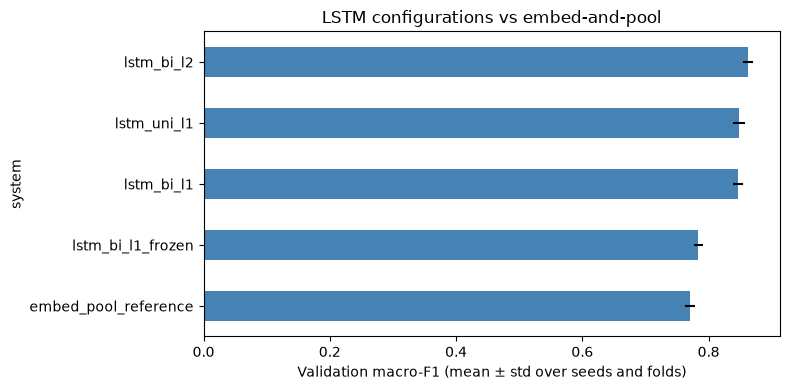

In [72]:
def lstm_mean_ci(values, confidence=0.95):
    values = np.asarray(values, dtype=float)
    half = stats.t.ppf((1 + confidence) / 2, len(values) - 1) * values.std(ddof=1) / np.sqrt(len(values))
    return values.mean(), values.mean() - half, values.mean() + half


lstm_summary_rows = []
for system_name, group in lstm_scores_df.groupby("system", sort=False):
    f1_mean, f1_low, f1_high = lstm_mean_ci(group["macro_f1"])
    lstm_summary_rows.append({
        "system": system_name, "n": len(group),
        "macro_f1": f1_mean, "macro_f1_ci95": f"[{f1_low:.3f}, {f1_high:.3f}]",
        "macro_f1_std": group["macro_f1"].std(ddof=1),
        "accuracy": group["accuracy"].mean(),
    })
lstm_summary_df = pd.DataFrame(lstm_summary_rows).sort_values("macro_f1", ascending=False)
save_table(lstm_summary_df, "lstm_summary", index=False)
display(lstm_summary_df.round(4))

lstm_only = lstm_summary_df[lstm_summary_df["system"].str.startswith("lstm")]
best_lstm = lstm_only.iloc[0]["system"]
print(f"Best LSTM configuration (by mean validation macro-F1): {best_lstm}")

lstm_paired = lstm_scores_df.pivot_table(index=["seed", "fold"], columns="system", values="macro_f1")
lstm_questions = [
    ("Bidirectional vs unidirectional (1 layer)", "lstm_bi_l1", "lstm_uni_l1"),
    ("Two vs one layer (bidirectional)", "lstm_bi_l2", "lstm_bi_l1"),
    ("Trainable vs frozen embeddings", "lstm_bi_l1", "lstm_bi_l1_frozen"),
    ("Best LSTM vs embed-and-pool", best_lstm, "embed_pool_reference"),
]
lstm_comparison_rows = []
for question, system_a, system_b in lstm_questions:
    if system_a not in lstm_paired or system_b not in lstm_paired:
        continue
    diff = (lstm_paired[system_a] - lstm_paired[system_b]).dropna()
    mean, low, high = lstm_mean_ci(diff)
    lstm_comparison_rows.append({
        "question": question, "A": system_a, "B": system_b, "n": len(diff),
        "mean_diff_A_minus_B": mean, "ci95_low": low, "ci95_high": high,
        "A_wins": int((diff > 0).sum()), "B_wins": int((diff < 0).sum()),
        "wilcoxon_p": stats.wilcoxon(diff).pvalue if (diff != 0).any() else 1.0,
    })
lstm_comparisons_df = pd.DataFrame(lstm_comparison_rows).set_index("question")
save_table(lstm_comparisons_df, "lstm_paired_comparisons")
display(lstm_comparisons_df.round(4))

axis = (
    lstm_scores_df.groupby("system", sort=False)["macro_f1"]
    .agg(["mean", "std"]).loc[lstm_summary_df["system"]]
    .plot.barh(y="mean", xerr="std", legend=False, figsize=(8, 4), color="steelblue")
)
axis.invert_yaxis()
axis.set_xlabel("Validation macro-F1 (mean ± std over seeds and folds)")
axis.set_title("LSTM configurations vs embed-and-pool")
plt.tight_layout()
plt.show()

## Over-fitting: learning curves

Cross-validation only keeps the best epoch, so to see *how* the models over-fit we train the best LSTM configuration and the same configuration without word dropout on one fold for more epochs and record the training and validation curves per epoch. A widening gap between training and validation loss, with validation loss rising while training loss keeps falling, indicates over-fitting.

Tokenizing texts...
Tokenization done! Time taken: 1.124 seconds
Dataloader done! Time taken: 0.020 seconds


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.5567 | train acc: 0.3718 | val loss: 1.3674 | val acc: 0.5007
Epoch 02 | train loss: 1.2885 | train acc: 0.5218 | val loss: 1.1495 | val acc: 0.5615
Epoch 03 | train loss: 1.0806 | train acc: 0.5825 | val loss: 0.8903 | val acc: 0.6753
Epoch 04 | train loss: 0.8302 | train acc: 0.6996 | val loss: 0.6218 | val acc: 0.7863
Epoch 05 | train loss: 0.6154 | train acc: 0.7977 | val loss: 0.4760 | val acc: 0.8465
Epoch 06 | train loss: 0.4999 | train acc: 0.8365 | val loss: 0.4008 | val acc: 0.8723
Epoch 07 | train loss: 0.4267 | train acc: 0.8617 | val loss: 0.3610 | val acc: 0.8852
Epoch 08 | train loss: 0.3759 | train acc: 0.8737 | val loss: 0.3384 | val acc: 0.8918
Epoch 09 | train loss: 0.3476 | train acc: 0.8848 | val loss: 0.3496 | val acc: 0.8835
Epoch 10 | train loss: 0.3264 | train acc: 0.8895 | val loss: 0.3334 | val acc: 0.8895
Epoch 11 | train loss: 0.2967 | train acc: 0.9001 | val loss: 0.3091 | val acc: 0.9022
Epoch 12 | train loss: 0.2825 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.5456 | train acc: 0.3811 | val loss: 1.3136 | val acc: 0.5108
Epoch 02 | train loss: 1.2458 | train acc: 0.5328 | val loss: 1.1177 | val acc: 0.5720
Epoch 03 | train loss: 1.0076 | train acc: 0.6113 | val loss: 0.8524 | val acc: 0.6875
Epoch 04 | train loss: 0.7016 | train acc: 0.7487 | val loss: 0.6109 | val acc: 0.7913
Epoch 05 | train loss: 0.4778 | train acc: 0.8413 | val loss: 0.4970 | val acc: 0.8358
Epoch 06 | train loss: 0.3603 | train acc: 0.8842 | val loss: 0.4570 | val acc: 0.8542
Epoch 07 | train loss: 0.2682 | train acc: 0.9150 | val loss: 0.3984 | val acc: 0.8805
Epoch 08 | train loss: 0.2124 | train acc: 0.9300 | val loss: 0.3856 | val acc: 0.8820
Epoch 09 | train loss: 0.1788 | train acc: 0.9413 | val loss: 0.3698 | val acc: 0.8875
Epoch 10 | train loss: 0.1379 | train acc: 0.9544 | val loss: 0.3933 | val acc: 0.8880
Epoch 11 | train loss: 0.1213 | train acc: 0.9587 | val loss: 0.3862 | val acc: 0.8855
Epoch 12 | train loss: 0.1086 | train acc: 

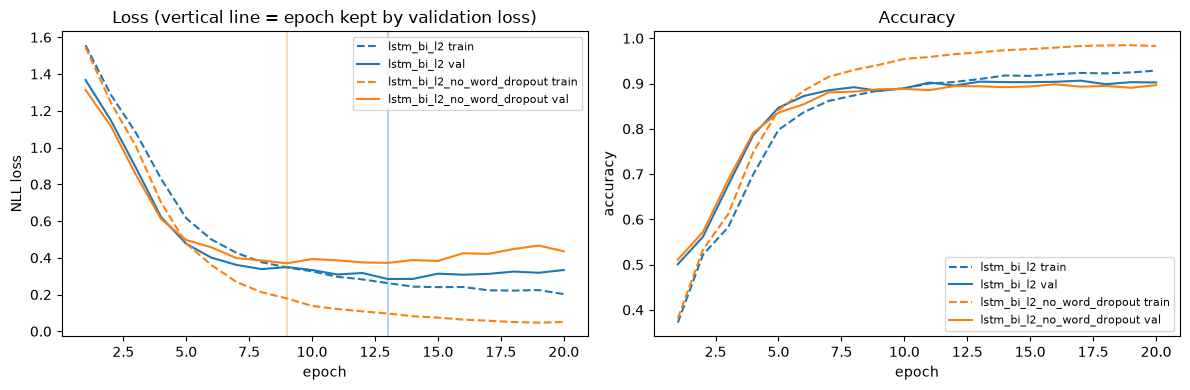

In [73]:
CURVE_EPOCHS = 20
curve_split = lstm_splits[LSTM_SEEDS[0]][0]
# the best configuration, and the same configuration without word dropout
curve_configs = OrderedDict({best_lstm: lstm_systems[best_lstm]})
no_word_dropout = copy.deepcopy(lstm_systems[best_lstm])
no_word_dropout["enc_kwargs"]["word_dropout"] = 0.0
curve_configs[f"{best_lstm}_no_word_dropout"] = no_word_dropout

def run_learning_curves():
    learning_curves = {}
    for system_name, config in curve_configs.items():
        random.seed(0)
        np.random.seed(0)
        torch.manual_seed(0)
        curve_folder = lstm_results_folder / "curves" / system_name
        curve_folder.mkdir(parents=True, exist_ok=True)
        metrics, best_epoch = part2.experiment.train(
            curve_split["training"], curve_split["validation"],
            lstm_tokenizer, lstm_embedding_model,
            num_classes=len(outcome_space),
            enc_type=config["enc_type"],
            enc_kwargs=dict(config["enc_kwargs"]),
            regressor_kwargs=dict(lstm_regressor_kwargs),
            opt_kwargs={**lstm_optimizer_kwargs, "num_epochs": CURVE_EPOCHS},
            device=LSTM_DEVICE,
            save_to=f"{curve_folder}/model",
        )
        learning_curves[system_name] = (metrics, best_epoch)
    return learning_curves


learning_curves = load_or_compute(
    "lstm_learning_curves",
    run_learning_curves,
    key={"configs": curve_configs, "regressor": lstm_regressor_kwargs,
         "optimizer": lstm_optimizer_kwargs, "epochs": CURVE_EPOCHS, "seed": LSTM_SEEDS[0],
         "class_weighted_loss": True},
)

curve_rows = [
    {"system": system_name, "epoch": epoch + 1,
     "train_loss": m["train_metrics"]["loss"], "train_accuracy": m["train_metrics"]["accuracy"],
     "val_loss": m["val_metrics"]["loss"], "val_accuracy": m["val_metrics"]["accuracy"],
     "kept_epoch": epoch == best_epoch}
    for system_name, (metrics, best_epoch) in learning_curves.items()
    for epoch, m in enumerate(metrics)
]
save_table(pd.DataFrame(curve_rows), "lstm_learning_curves", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for system_name, (metrics, best_epoch) in learning_curves.items():
    epochs = np.arange(1, len(metrics) + 1)
    train_loss = [m["train_metrics"]["loss"] for m in metrics]
    val_loss = [m["val_metrics"]["loss"] for m in metrics]
    train_acc = [m["train_metrics"]["accuracy"] for m in metrics]
    val_acc = [m["val_metrics"]["accuracy"] for m in metrics]
    line, = axes[0].plot(epochs, train_loss, "--", label=f"{system_name} train")
    axes[0].plot(epochs, val_loss, "-", color=line.get_color(), label=f"{system_name} val")
    axes[0].axvline(best_epoch + 1, color=line.get_color(), alpha=0.3)
    axes[1].plot(epochs, train_acc, "--", color=line.get_color(), label=f"{system_name} train")
    axes[1].plot(epochs, val_acc, "-", color=line.get_color(), label=f"{system_name} val")
axes[0].set(xlabel="epoch", ylabel="NLL loss", title="Loss (vertical line = epoch kept by validation loss)")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
for axis in axes:
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Effect of training-data size

Pretrained embeddings and architectural inductive biases should matter most when labelled data is scarce. We train the best LSTM and the embed-and-pool reference on increasing fractions of one training fold (the same random subset for both systems at each size) and evaluate on the full validation fold. This uses a single seed and fold, so it shows trends rather than precise differences.

Tokenizing texts...
Tokenization done! Time taken: 0.406 seconds
Dataloader done! Time taken: 0.010 seconds


  0%|          | 0/90 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.7516 | train acc: 0.3100 | val loss: 1.6821 | val acc: 0.3473
Epoch 02 | train loss: 1.6683 | train acc: 0.3167 | val loss: 1.5784 | val acc: 0.3473
Epoch 03 | train loss: 1.6228 | train acc: 0.3383 | val loss: 1.5721 | val acc: 0.3473
Epoch 04 | train loss: 1.6271 | train acc: 0.2950 | val loss: 1.5708 | val acc: 0.3473
Epoch 05 | train loss: 1.6130 | train acc: 0.3300 | val loss: 1.5786 | val acc: 0.3473
Epoch 06 | train loss: 1.6148 | train acc: 0.3383 | val loss: 1.5716 | val acc: 0.3473
Epoch 07 | train loss: 1.6073 | train acc: 0.3500 | val loss: 1.5631 | val acc: 0.3473
Epoch 08 | train loss: 1.6069 | train acc: 0.3233 | val loss: 1.5602 | val acc: 0.3478
Epoch 09 | train loss: 1.5950 | train acc: 0.3517 | val loss: 1.5529 | val acc: 0.3748
Epoch 10 | train loss: 1.5841 | train acc: 0.3767 | val loss: 1.5362 | val acc: 0.4217
Epoch 11 | train loss: 1.5459 | train acc: 0.4083 | val loss: 1.5115 | val acc: 0.4193
Epoch 12 | train loss: 1.5226 | train acc: 

  0%|          | 0/90 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.7627 | train acc: 0.2117 | val loss: 1.6791 | val acc: 0.2902
Epoch 02 | train loss: 1.6861 | train acc: 0.3183 | val loss: 1.6111 | val acc: 0.3638
Epoch 03 | train loss: 1.6407 | train acc: 0.3217 | val loss: 1.5800 | val acc: 0.3477
Epoch 04 | train loss: 1.6287 | train acc: 0.3267 | val loss: 1.5663 | val acc: 0.3475
Epoch 05 | train loss: 1.6202 | train acc: 0.3400 | val loss: 1.5605 | val acc: 0.3502
Epoch 06 | train loss: 1.6086 | train acc: 0.3467 | val loss: 1.5573 | val acc: 0.3613
Epoch 07 | train loss: 1.6055 | train acc: 0.3633 | val loss: 1.5558 | val acc: 0.4288
Epoch 08 | train loss: 1.5904 | train acc: 0.3583 | val loss: 1.5520 | val acc: 0.4168
Epoch 09 | train loss: 1.5867 | train acc: 0.3517 | val loss: 1.5473 | val acc: 0.3787
Epoch 10 | train loss: 1.5829 | train acc: 0.3550 | val loss: 1.5438 | val acc: 0.3920
Epoch 11 | train loss: 1.5824 | train acc: 0.3833 | val loss: 1.5390 | val acc: 0.4173
Epoch 12 | train loss: 1.5812 | train acc: 

  0%|          | 0/64 [00:00<?, ?it/s]

... (12 outputs left out)

Epoch 01 | train loss: 1.5723 | train acc: 0.3553 | val loss: 1.3750 | val acc: 0.4930
Epoch 02 | train loss: 1.2688 | train acc: 0.5228 | val loss: 1.1144 | val acc: 0.5802
Epoch 03 | train loss: 0.9750 | train acc: 0.6398 | val loss: 0.7416 | val acc: 0.7352
Epoch 04 | train loss: 0.7212 | train acc: 0.7554 | val loss: 0.5761 | val acc: 0.8108
Epoch 05 | train loss: 0.5664 | train acc: 0.8188 | val loss: 0.4601 | val acc: 0.8573
Epoch 06 | train loss: 0.4728 | train acc: 0.8508 | val loss: 0.3870 | val acc: 0.8813
Epoch 07 | train loss: 0.4074 | train acc: 0.8688 | val loss: 0.3431 | val acc: 0.8885
Epoch 08 | train loss: 0.3713 | train acc: 0.8748 | val loss: 0.3356 | val acc: 0.8878
Epoch 09 | train loss: 0.3368 | train acc: 0.8862 | val loss: 0.3048 | val acc: 0.8977
Epoch 10 | train loss: 0.2953 | train acc: 0.8998 | val loss: 0.3025 | val acc: 0.9013
Epoch 11 | train loss: 0.3051 | train acc: 0.8959 | val loss: 0.2870 | val acc: 0.9028
Epoch 12 | train loss: 0.2894 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.5871 | train acc: 0.3621 | val loss: 1.4917 | val acc: 0.4675
Epoch 02 | train loss: 1.4272 | train acc: 0.4574 | val loss: 1.2829 | val acc: 0.5258
Epoch 03 | train loss: 1.2765 | train acc: 0.5163 | val loss: 1.1482 | val acc: 0.5593
Epoch 04 | train loss: 1.1408 | train acc: 0.5667 | val loss: 1.0276 | val acc: 0.6145
Epoch 05 | train loss: 1.0153 | train acc: 0.6140 | val loss: 0.9240 | val acc: 0.6563
Epoch 06 | train loss: 0.8973 | train acc: 0.6645 | val loss: 0.8473 | val acc: 0.6783
Epoch 07 | train loss: 0.7978 | train acc: 0.7005 | val loss: 0.7547 | val acc: 0.7208
Epoch 08 | train loss: 0.6934 | train acc: 0.7436 | val loss: 0.6973 | val acc: 0.7473
Epoch 09 | train loss: 0.6102 | train acc: 0.7740 | val loss: 0.6487 | val acc: 0.7630
Epoch 10 | train loss: 0.5435 | train acc: 0.8047 | val loss: 0.6127 | val acc: 0.7762
Epoch 11 | train loss: 0.4825 | train acc: 0.8221 | val loss: 0.5887 | val acc: 0.7877
Epoch 12 | train loss: 0.4290 | train acc: 

system,embed_pool_reference,lstm_bi_l2
n_train,,
600,0.2559,0.2169
1200,0.3462,0.3368
3000,0.5608,0.7077
6000,0.6865,0.8093
12000,0.7652,0.8589


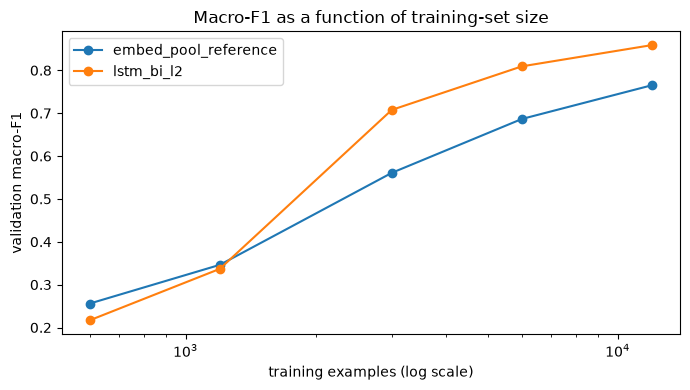

In [74]:
DATA_FRACTIONS = [0.05, 0.1, 0.25, 0.5, 1.0]
size_split = lstm_splits[LSTM_SEEDS[0]][0]
size_rng = np.random.default_rng(0)
size_order = size_rng.permutation(len(size_split["training"]))   # nested subsets: smaller ones are prefixes
size_gold = [label for _, label in size_split["validation"]]

def run_data_size_experiment():
    data_size_rows = []
    for fraction in DATA_FRACTIONS:
        n_train = int(round(fraction * len(size_split["training"])))
        subset = [size_split["training"][i] for i in size_order[:n_train]]
        for system_name in [best_lstm, "embed_pool_reference"]:
            config = lstm_systems[system_name]
            random.seed(0)
            np.random.seed(0)
            torch.manual_seed(0)
            size_folder = lstm_results_folder / "data-size" / system_name / f"frac-{fraction}"
            size_folder.mkdir(parents=True, exist_ok=True)
            # small subsets need more epochs to converge; the best epoch is still chosen on validation loss
            num_epochs = max(lstm_optimizer_kwargs["num_epochs"], int(np.ceil(lstm_optimizer_kwargs["num_epochs"] / fraction ** 0.5)))
            metrics, best_epoch = part2.experiment.train(
                subset, size_split["validation"],
                lstm_tokenizer, lstm_embedding_model,
                num_classes=len(outcome_space),
                enc_type=config["enc_type"],
                enc_kwargs=dict(config["enc_kwargs"]),
                regressor_kwargs=dict(lstm_regressor_kwargs),
                opt_kwargs={**lstm_optimizer_kwargs, "num_epochs": num_epochs},
                device=LSTM_DEVICE,
                save_to=f"{size_folder}/model",
            )
            predictions = [p for batch in metrics[best_epoch]["val_metrics"]["predictions"] for p in batch]
            data_size_rows.append({
                "system": system_name, "fraction": fraction, "n_train": n_train,
                "macro_f1": f1_score(size_gold, predictions, average="macro", zero_division=0),
                "accuracy": metrics[best_epoch]["val_metrics"]["accuracy"],
            })
    return data_size_rows


data_size_rows = load_or_compute(
    "lstm_data_size",
    run_data_size_experiment,
    key={"fractions": DATA_FRACTIONS, "systems": {n: lstm_systems[n] for n in [best_lstm, "embed_pool_reference"]},
         "regressor": lstm_regressor_kwargs, "optimizer": lstm_optimizer_kwargs, "seed": LSTM_SEEDS[0],
         "class_weighted_loss": True},
)

data_size_df = pd.DataFrame(data_size_rows)
save_table(data_size_df, "lstm_data_size", index=False)
display(data_size_df.pivot(index="n_train", columns="system", values="macro_f1").round(4))

fig, axis = plt.subplots(figsize=(7, 4))
for system_name, group in data_size_df.groupby("system"):
    axis.plot(group["n_train"], group["macro_f1"], marker="o", label=system_name)
axis.set_xscale("log")
axis.set(xlabel="training examples (log scale)", ylabel="validation macro-F1",
         title="Macro-F1 as a function of training-set size")
axis.legend()
plt.tight_layout()
plt.show()

## LSTM test evaluation

As with embed-and-pool, the test set is used once, after all choices were made on validation folds: every cross-validation model of the best LSTM and of the embed-and-pool reference is evaluated on the original test set.

In [75]:
lstm_test_texts = list(dataset["test"]["text"])
lstm_test_labels = np.asarray(dataset["test"]["label"], dtype=int)

lstm_test_rows = []
for system_name in [best_lstm, "embed_pool_reference"]:
    for _, row in lstm_scores_df[lstm_scores_df["system"] == system_name].iterrows():
        trained = part2.experiment.load(row["model_path"], lstm_embedding_model, device=LSTM_DEVICE)
        predictions = part2.experiment.predict_logprobs(
            trained, lstm_tokenizer, lstm_test_texts, 256, LSTM_DEVICE
        ).argmax(-1)
        lstm_test_rows.append({
            "system": system_name, "seed": row["seed"], "fold": row["fold"],
            "accuracy": float((predictions == lstm_test_labels).mean()),
            "macro_f1": f1_score(lstm_test_labels, predictions, average="macro", zero_division=0),
        })
        del trained

lstm_test_df = pd.DataFrame(lstm_test_rows)
save_table(lstm_test_df, "lstm_test_scores", index=False)
display(
    lstm_test_df.groupby("system", sort=False)[["macro_f1", "accuracy"]]
    .agg(["mean", "std", "count"]).round(4)
)

macro_f1               accuracy              
                         mean     std count     mean     std count
system                                                            
lstm_bi_l2             0.8562  0.0089     9   0.9038  0.0055     9
embed_pool_reference   0.7712  0.0099     9   0.8366  0.0058     9

## LSTM interpretation

*To be written after running this section.* Points to address, using the tables above:

* **Direction and depth:** does bidirectionality or a second layer give a paired improvement whose interval excludes zero, or are the differences within seed/fold noise?
* **Embeddings:** how large is the gap between trainable and frozen embeddings, and is it similar to the embed-and-pool case?
* **Over-fitting:** at which epoch does validation loss start to rise, and does word dropout delay this or narrow the train/validation gap?
* **Data size:** at which training-set size (if any) does the LSTM overtake embed-and-pool?
* **Overall:** does the best LSTM improve meaningfully over embed-and-pool on both validation and test, and is the improvement worth the extra training cost?